# BÀI TẬP DỰ ÁN: PHÂN TÍCH & KHAI THÁC DỮ LIỆU — BỘ DỮ LIỆU WINE
**File tổng hợp của nhóm:** `Eda_pca.ipynb`

**Bộ dữ liệu:** Wine recognition (UCI) — 178 mẫu rượu vang Ý, 13 thuộc tính hóa học liên tục, nhãn ∈ {1, 2, 3} (3 giống nho/vùng trồng).

**Cấu trúc 4 phần theo yêu cầu đề bài:**
1. **Đọc dữ liệu và khám phá** — đọc Excel → CSV, chia train/test 80/20 phân tầng (seed 42), kiểm soát chất lượng, thống kê mô tả, EDA trực quan.
2. **Tạo data mới và trực quan hóa** — chuẩn hóa StandardScaler (fit trên train), PCA, biểu diễn 2D theo nhãn.
3. **Huấn luyện mô hình phân loại** — KNN, Gaussian Naive Bayes, Random Forest; nested stratified 10-fold CV, tinh chỉnh tham số, độ đo F-Score.
4. **Gom cụm dữ liệu** — K-Means và DBSCAN (không dùng cột nhãn), trực quan trên PCA 2D, đánh giá bằng Adjusted Rand Index.

**Cách chạy:** chạy tuần tự từ đầu. Cần đặt tệp Excel nguồn vào `datasets/raw/` (một tệp `.xlsx` duy nhất); kết quả CSV/PNG sinh ra trong `datasets/output/`. Môi trường: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `openpyxl`, `ipykernel`.

## Thiết lập phân tích

Notebook tự tìm thư mục dự án từ thư mục làm việc hiện tại hoặc các thư mục cha thông qua `datasets/raw`. Tệp Excel được chuyển thành CSV trước khi đọc. Không sử dụng đường dẫn tuyệt đối cố định.

Dữ liệu được chia train/test 80/20 có phân tầng theo nhãn trước khi tiền xử lý. Thống kê khám phá và các tham số tiền xử lý được xác định từ train; test chỉ áp dụng các phép biến đổi đã fit trên train.

Các tệp CSV của từng bước được lưu riêng trong **`datasets/output`**; biểu đồ PNG lưu trong **`output` ở gốc dự án**. Hai thư mục này phải có sẵn như cấu trúc dự án. Chạy lại sẽ cập nhật các tệp cùng tên do notebook tạo, không xóa các tệp khác.

Môi trường cần có `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `ipykernel`, `openpyxl`. Chạy các cell từ đầu để tái lập toàn bộ kết quả.

In [1]:
from pathlib import Path
import re
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

EXCEL_SHEET = "wine.data"
TARGET = "class"
TEST_SIZE = 0.20
RANDOM_STATE = 42

plt.rcParams.update({"figure.dpi": 120, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlepad": 12})
pd.set_option("display.max_columns", 20)
print("Môi trường:", "Python", platform.python_version(), "| pandas", pd.__version__,
      "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__)

Môi trường: Python 3.14.6 | pandas 3.0.3 | numpy 2.5.1 | scikit-learn 1.9.0 | matplotlib 3.11.0


In [2]:
# Tìm gốc dự án và các thư mục đã có
current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (folder for folder in [current_dir, *current_dir.parents]
     if (folder / "datasets" / "raw").is_dir()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy datasets/raw. Mở notebook từ dự án hoặc một thư mục con.")

DATA_DIR = PROJECT_ROOT / "datasets" / "raw"

# CSV và biểu đồ cùng lưu trong datasets/output 
OUTPUT_DIR = PROJECT_ROOT / "datasets" / "output"
FIGURE_DIR = OUTPUT_DIR

# Giữ nguyên thư mục và các file hiện có; chỉ tạo nếu chưa tồn tại.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for directory in (OUTPUT_DIR, FIGURE_DIR):
    if not directory.is_dir():
        raise FileNotFoundError(f"Thiếu thư mục đầu ra theo cấu trúc dự án: {directory}")

xlsx_files = sorted(p for p in DATA_DIR.glob("*.xlsx") if not p.name.startswith("~$"))
if not xlsx_files:
    raise FileNotFoundError(f"Không có tệp Excel trong {DATA_DIR}")
if len(xlsx_files) > 1:
    raise ValueError("Có nhiều tệp Excel; cần xác định nguồn dữ liệu: " + ", ".join(p.name for p in xlsx_files))
xlsx_path = xlsx_files[0]

# Mỗi bảng được lưu vào một tệp riêng ngay tại bước tạo bảng.
saved_files = []
def save_table(table, filename, index=False):
    destination = OUTPUT_DIR / filename
    table.to_csv(destination, index=index, encoding="utf-8-sig")
    saved_files.append({"Tệp": filename, "Số dòng": len(table), "Thư mục": "datasets/output"})
    return destination

print("Excel nguồn:", xlsx_path)
print("CSV đầu ra:", OUTPUT_DIR)
print("Biểu đồ:", FIGURE_DIR)

Excel nguồn: C:\Users\ASUS\Documents\code\thực hành\bài tập nhóm data mining\datasets\raw\D00 - wine.data.xlsx
CSV đầu ra: C:\Users\ASUS\Documents\code\thực hành\bài tập nhóm data mining\datasets\output
Biểu đồ: C:\Users\ASUS\Documents\code\thực hành\bài tập nhóm data mining\datasets\output


## 1. Đọc dữ liệu và khám phá
### 1.1. Nguồn dữ liệu và cấu trúc thuộc tính

Đọc trực tiếp tệp nguồn, bảo toàn dữ liệu ban đầu trong `df_raw`. Chuẩn hóa tên cột nhằm bảo đảm thao tác nhất quán; giữ nguyên ý nghĩa và giá trị của các thuộc tính. Cấu trúc kỳ vọng được kiểm tra theo tên thay vì gán lại tên theo vị trí cột.

In [3]:
# Chuyển XLSX thành CSV, sau đó đọc CSV vào bộ nhớ.
with pd.ExcelFile(xlsx_path, engine="openpyxl") as workbook:
    if EXCEL_SHEET not in workbook.sheet_names:
        raise ValueError(f"Không có sheet {EXCEL_SHEET!r}. Các sheet hiện có: {workbook.sheet_names}")
    df_excel = pd.read_excel(workbook, sheet_name=EXCEL_SHEET)
if df_excel.empty:
    raise ValueError("Sheet dữ liệu không chứa bản ghi.")

csv_path = save_table(df_excel, "00_wine_from_xlsx.csv")
df_raw = pd.read_csv(csv_path, encoding="utf-8-sig")
print("CSV đã chuyển từ Excel:", csv_path)
print("Kích thước dữ liệu nguồn:", df_raw.shape)
display(df_raw.head())

CSV đã chuyển từ Excel: C:\Users\ASUS\Documents\code\thực hành\bài tập nhóm data mining\datasets\output\00_wine_from_xlsx.csv
Kích thước dữ liệu nguồn: (178, 14)


,Class,1) Alcohol,2) Malic acid,3) Ash,4) Alcalinity of ash,5) Magnesium,6) Total phenols,7) Flavanoids,8) Nonflavanoid phenols,9) Proanthocyanins,10)Color intensity,11)Hue,12)OD280/OD315 of diluted wines,13)Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


### Chia dữ liệu trước tiền xử lý

Chia 80% train và 20% test, phân tầng theo nhãn, với seed cố định. Chỉ kiểm tra nhãn tối thiểu để thực hiện phép chia; chưa chuẩn hóa, tính ngưỡng ngoại lai hoặc fit PCA. Lưu riêng `train_data.csv`, `test_data.csv` với các cột và giá trị gốc. `01_split_membership.csv` ghi lại chỉ số dòng nguồn để truy vết. Các phân tích khám phá phía sau dùng train.

In [4]:
label_columns = [col for col in df_raw.columns if str(col).strip().lower() == TARGET]
if len(label_columns) != 1:
    raise ValueError("Cần đúng một cột nhãn Class để chia phân tầng.")
raw_target = label_columns[0]
if df_raw[raw_target].isna().any():
    raise ValueError("Có nhãn thiếu; cần kiểm tra nguồn trước khi chia dữ liệu.")

train_raw, test_raw = train_test_split(
    df_raw, test_size=TEST_SIZE, stratify=df_raw[raw_target], random_state=RANDOM_STATE
)
assert set(train_raw.index).isdisjoint(test_raw.index)
assert len(train_raw) + len(test_raw) == len(df_raw)
save_table(train_raw, "train_data.csv")
save_table(test_raw, "test_data.csv")
membership = pd.concat([
    pd.DataFrame({"source_row_index": train_raw.index, "split": "train"}),
    pd.DataFrame({"source_row_index": test_raw.index, "split": "test"})
], ignore_index=True).sort_values("source_row_index")
save_table(membership, "01_split_membership.csv")
display(pd.DataFrame({"Train": train_raw[raw_target].value_counts(),
                      "Test": test_raw[raw_target].value_counts()}).sort_index())
print(f"Train: {train_raw.shape}; Test: {test_raw.shape}")

,Train,Test
Class,,
1,47,12
2,57,14
3,38,10


Train: (142, 14); Test: (36, 14)


In [5]:
def clean_column_name(name):
    name = re.sub(r"^\d+\)\s*", "", str(name).strip())
    return re.sub(r"\s+", "_", name.lower().replace("/", "_"))

FEATURES = ["alcohol", "malic_acid", "ash", "alcalinity_of_ash", "magnesium",
            "total_phenols", "flavanoids", "nonflavanoid_phenols", "proanthocyanins",
            "color_intensity", "hue", "od280_od315_of_diluted_wines", "proline"]
train_named = train_raw.rename(columns=clean_column_name).copy()
test_named = test_raw.rename(columns=clean_column_name).copy()
df = train_named  # EDA chỉ dùng train.
if df.columns.duplicated().any():
    raise ValueError("Tên cột bị trùng sau chuẩn hóa.")
expected = {"class", *FEATURES}
if set(df.columns) != expected:
    raise ValueError(f"Sai cấu trúc. Thiếu: {expected - set(df.columns)}; thừa: {set(df.columns) - expected}")
display(pd.DataFrame({"Tên gốc": df_raw.columns, "Tên chuẩn hóa": df.columns}))
save_table(train_named, "02_train_columns_cleaned.csv")
save_table(test_named, "02_test_columns_cleaned.csv")

,Tên gốc,Tên chuẩn hóa
0,Class,class
1,1) Alcohol,alcohol
2,2) Malic acid,malic_acid
3,3) Ash,ash
4,4) Alcalinity of ash,alcalinity_of_ash
5,5) Magnesium,magnesium
6,6) Total phenols,total_phenols
7,7) Flavanoids,flavanoids
8,8) Nonflavanoid phenols,nonflavanoid_phenols
9,9) Proanthocyanins,proanthocyanins


WindowsPath('C:/Users/ASUS/Documents/code/thực hành/bài tập nhóm data mining/datasets/output/02_test_columns_cleaned.csv')

### 1.2. Quy mô, kiểu dữ liệu và phân bố nhãn

Phân biệt **kích thước bảng** (số mẫu × tổng số cột), **số chiều đặc trưng** (không tính nhãn) và **số trục DataFrame** (`ndim`). Kiểu lưu trữ số nguyên không đồng nghĩa với biến phân loại: Magnesium và Proline vẫn là các đại lượng đo được đưa vào phân tích liên tục.

Các thống kê trong mục này và các biểu đồ khám phá phía sau được tính trên tập train.

In [6]:
display(pd.DataFrame({"Thông tin": ["Số mẫu", "Tổng số cột", "Số đặc trưng", "Số cột nhãn", "Số trục DataFrame"],
                      "Giá trị": [len(df), df.shape[1], len(FEATURES), 1, df.ndim]}))
display(pd.DataFrame({"Kiểu dữ liệu": df.dtypes.astype(str), "Số giá trị có dữ liệu": df.notna().sum()}))
df.info()
label_counts = df["class"].value_counts(dropna=False).sort_index()
display(label_counts.rename("Số mẫu").to_frame().assign(Ty_le_phan_tram=lambda t: (100*t["Số mẫu"]/len(df)).round(2)))
save_table(df.dtypes.astype(str).rename("dtype").to_frame(), "03_train_dtypes.csv", index=True)
save_table(label_counts.rename("count").to_frame(), "03_train_class_counts.csv", index=True)

,Thông tin,Giá trị
0,Số mẫu,142
1,Tổng số cột,14
2,Số đặc trưng,13
3,Số cột nhãn,1
4,Số trục DataFrame,2


,Kiểu dữ liệu,Số giá trị có dữ liệu
class,int64,142
alcohol,float64,142
malic_acid,float64,142
ash,float64,142
alcalinity_of_ash,float64,142
magnesium,int64,142
total_phenols,float64,142
flavanoids,float64,142
nonflavanoid_phenols,float64,142
proanthocyanins,float64,142


<class 'pandas.DataFrame'>
Index: 142 entries, 36 to 131
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   class                         142 non-null    int64  
 1   alcohol                       142 non-null    float64
 2   malic_acid                    142 non-null    float64
 3   ash                           142 non-null    float64
 4   alcalinity_of_ash             142 non-null    float64
 5   magnesium                     142 non-null    int64  
 6   total_phenols                 142 non-null    float64
 7   flavanoids                    142 non-null    float64
 8   nonflavanoid_phenols          142 non-null    float64
 9   proanthocyanins               142 non-null    float64
 10  color_intensity               142 non-null    float64
 11  hue                           142 non-null    float64
 12  od280_od315_of_diluted_wines  142 non-null    float64
 13  proline             

,Số mẫu,Ty_le_phan_tram
class,,
1,47,33.10
2,57,40.14
3,38,26.76


WindowsPath('C:/Users/ASUS/Documents/code/thực hành/bài tập nhóm data mining/datasets/output/03_train_class_counts.csv')

### 1.3. Kiểm soát chất lượng và thống kê mô tả

Kiểm tra giá trị thiếu, giá trị không chuyển được sang số, vô hạn, nhãn ngoài miền và bản ghi trùng hoàn toàn. Nếu phát hiện dữ liệu không hợp lệ, quy trình dừng để xác minh nguồn; không tự ý điền khuyết hoặc sửa giá trị. Các bản ghi trùng hoàn toàn được loại riêng trong từng tập và ghi nhận số lượng. Nếu cùng một bản ghi xuất hiện ở cả train và test, quy trình dừng để tránh chồng lấn giữa hai tập.

Bảng thống kê báo cáo **Min, Max, Mean** theo yêu cầu, bổ sung độ lệch chuẩn và trung vị. Nhãn phân loại không được đưa vào bảng thống kê thuộc tính liên tục.

In [7]:
def check_and_clean(frame, split_name):
    numeric = frame.apply(pd.to_numeric, errors="coerce")
    invalid_numeric = frame.notna() & numeric.isna()
    report = pd.DataFrame({"Thiếu": frame.isna().sum(), "Không phải số": invalid_numeric.sum(),
        "Vô hạn": pd.Series(np.isinf(numeric.to_numpy(dtype=float)).sum(axis=0), index=frame.columns)})
    save_table(report, f"03_{split_name}_quality.csv", index=True)
    if report.to_numpy().sum() != 0:
        raise ValueError(f"Tập {split_name} có giá trị thiếu/không phải số/vô hạn. Kiểm tra nguồn trước khi tiếp tục.")
    if not numeric[TARGET].isin([1, 2, 3]).all():
        raise ValueError(f"Nhãn của tập {split_name} phải thuộc {{1, 2, 3}}.")
    duplicates = int(numeric.duplicated().sum())
    cleaned = numeric.drop_duplicates().copy()
    cleaned[TARGET] = cleaned[TARGET].astype(int)
    save_table(cleaned, f"04_{split_name}_clean.csv")
    return cleaned, report, duplicates

train_clean, quality, duplicate_count = check_and_clean(train_named, "train")
test_clean, test_quality, test_duplicate_count = check_and_clean(test_named, "test")
overlap = train_clean.merge(test_clean, how="inner", on=[TARGET, *FEATURES])
if not overlap.empty:
    raise ValueError("Có bản ghi trùng giữa train và test. Cần chia lại theo nhóm bản ghi để tránh rò rỉ.")

df_clean = train_clean  # Giữ các phân tích khám phá hiện có trên train.
display(quality)
print(f"Train sau làm sạch: {train_clean.shape}; bỏ {duplicate_count} dòng trùng.")
print(f"Test sau làm sạch: {test_clean.shape}; bỏ {test_duplicate_count} dòng trùng.")
stats = df_clean[FEATURES].agg(["min", "max", "mean", "std", "median"]).T
display(stats.round(3))
save_table(stats, "05_train_descriptive_statistics.csv", index=True)

X_train, y_train = train_clean[FEATURES].copy(), train_clean[TARGET].copy()
X_test, y_test = test_clean[FEATURES].copy(), test_clean[TARGET].copy()
save_table(X_train, "05_X_train_raw.csv")
save_table(X_test, "05_X_test_raw.csv")
save_table(y_train.to_frame(), "y_train.csv")
save_table(y_test.to_frame(), "y_test.csv")
save_table(pd.DataFrame({"source_row_index": X_train.index}), "05_train_row_order.csv")
save_table(pd.DataFrame({"source_row_index": X_test.index}), "05_test_row_order.csv")

,Thiếu,Không phải số,Vô hạn
class,0,0,0
alcohol,0,0,0
malic_acid,0,0,0
ash,0,0,0
alcalinity_of_ash,0,0,0
magnesium,0,0,0
total_phenols,0,0,0
flavanoids,0,0,0
nonflavanoid_phenols,0,0,0
proanthocyanins,0,0,0


Train sau làm sạch: (142, 14); bỏ 0 dòng trùng.
Test sau làm sạch: (36, 14); bỏ 0 dòng trùng.


,min,max,mean,std,median
alcohol,11.03,14.83,12.971,0.803,13.010
malic_acid,0.74,5.80,2.340,1.101,1.810
ash,1.36,3.22,2.365,0.268,2.360
alcalinity_of_ash,10.60,30.00,19.625,3.381,19.500
magnesium,70.00,162.00,99.634,14.937,97.000
total_phenols,0.98,3.88,2.274,0.621,2.335
flavanoids,0.34,3.74,1.985,0.952,2.135
nonflavanoid_phenols,0.13,0.63,0.360,0.119,0.340
proanthocyanins,0.42,3.58,1.600,0.580,1.560
color_intensity,1.28,13.00,4.990,2.335,4.640


WindowsPath('C:/Users/ASUS/Documents/code/thực hành/bài tập nhóm data mining/datasets/output/05_test_row_order.csv')

In [8]:
display(Markdown(
    f"**Đánh giá chất lượng dữ liệu.** Tệp nguồn có **{len(df_raw):,} bản ghi** và **{df_raw.shape[1]} cột**. "
    f"Kiểm tra trên tập train ghi nhận **{int(quality['Thiếu'].sum())} giá trị thiếu**, "
    f"**{int(quality['Không phải số'].sum())} giá trị không hợp lệ về kiểu số**, "
    f"**{int(quality['Vô hạn'].sum())} giá trị vô hạn** và **{duplicate_count} bản ghi trùng hoàn toàn**. "
    f"Sau xử lý, tập train dùng để phân tích có **{len(df_clean):,} bản ghi**, **{len(FEATURES)} đặc trưng** "
    f"và **{df_clean[TARGET].nunique()} lớp**. Test được xử lý và lưu riêng; không thực hiện điền khuyết hoặc thay thế giá trị."
))

**Đánh giá chất lượng dữ liệu.** Tệp nguồn có **178 bản ghi** và **14 cột**. Kiểm tra trên tập train ghi nhận **0 giá trị thiếu**, **0 giá trị không hợp lệ về kiểu số**, **0 giá trị vô hạn** và **0 bản ghi trùng hoàn toàn**. Sau xử lý, tập train dùng để phân tích có **142 bản ghi**, **13 đặc trưng** và **3 lớp**. Test được xử lý và lưu riêng; không thực hiện điền khuyết hoặc thay thế giá trị.

### 1.4. Cơ cấu các lớp

Phân bố nhãn cho biết mức độ đại diện của từng lớp trong tập dữ liệu. Số lượng và tỷ trọng được báo cáo trước khi diễn giải sự phân tách giữa các lớp trên không gian đặc trưng.

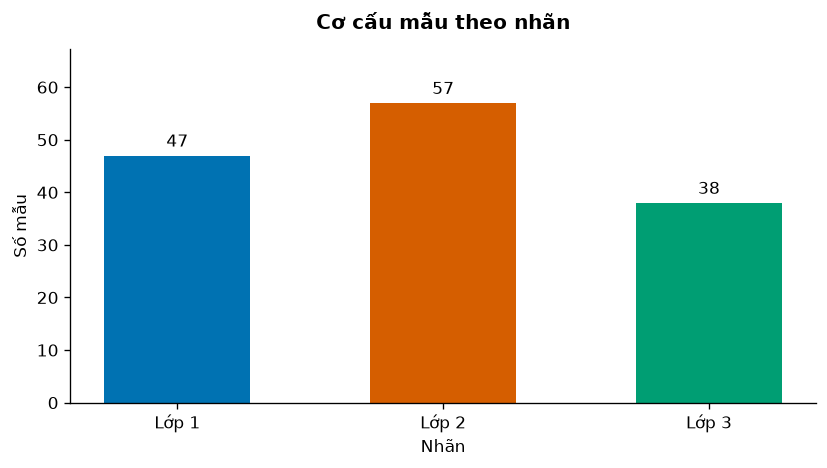

**Phân tích.** lớp 1: 47 mẫu (33.10%); lớp 2: 57 mẫu (40.14%); lớp 3: 38 mẫu (26.76%). Tỷ lệ số mẫu giữa lớp lớn nhất và nhỏ nhất là **1.50 lần**. Khi đọc các biểu đồ theo lớp, cần phân biệt mật độ điểm do quy mô mẫu với mức độ phân tán thực tế của thuộc tính.

In [9]:
classes = sorted(df_clean[TARGET].unique())
palette = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00"]
CLASS_COLORS = {k: palette[i % len(palette)] for i, k in enumerate(classes)}
counts = df_clean[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([f"Lớp {k}" for k in counts.index], counts.values,
              color=[CLASS_COLORS[k] for k in counts.index], width=0.55)
ax.bar_label(bars, padding=3)
ax.set(title="Cơ cấu mẫu theo nhãn", xlabel="Nhãn", ylabel="Số mẫu", ylim=(0, counts.max()*1.18))
plt.tight_layout()
fig.savefig(FIGURE_DIR / "01_train_class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()
shares = counts / counts.sum() * 100
distribution_text = "; ".join(f"lớp {k}: {counts[k]} mẫu ({shares[k]:.2f}%)" for k in counts.index)
display(Markdown(f"**Phân tích.** {distribution_text}. Tỷ lệ số mẫu giữa lớp lớn nhất và nhỏ nhất "
                 f"là **{counts.max()/counts.min():.2f} lần**. Khi đọc các biểu đồ theo lớp, "
                 "cần phân biệt mật độ điểm do quy mô mẫu với mức độ phân tán thực tế của thuộc tính."))

### 1.5. Phân phối và khác biệt thang đo

Mỗi thuộc tính được hiển thị trên trục riêng để bảo toàn đơn vị đo. Độ lệch phân phối (skewness) hỗ trợ nhận diện tính bất đối xứng; không được dùng riêng lẻ làm căn cứ loại biến hoặc áp dụng biến đổi log. Chênh lệch thang đo là cơ sở lựa chọn chuẩn hóa trước PCA.

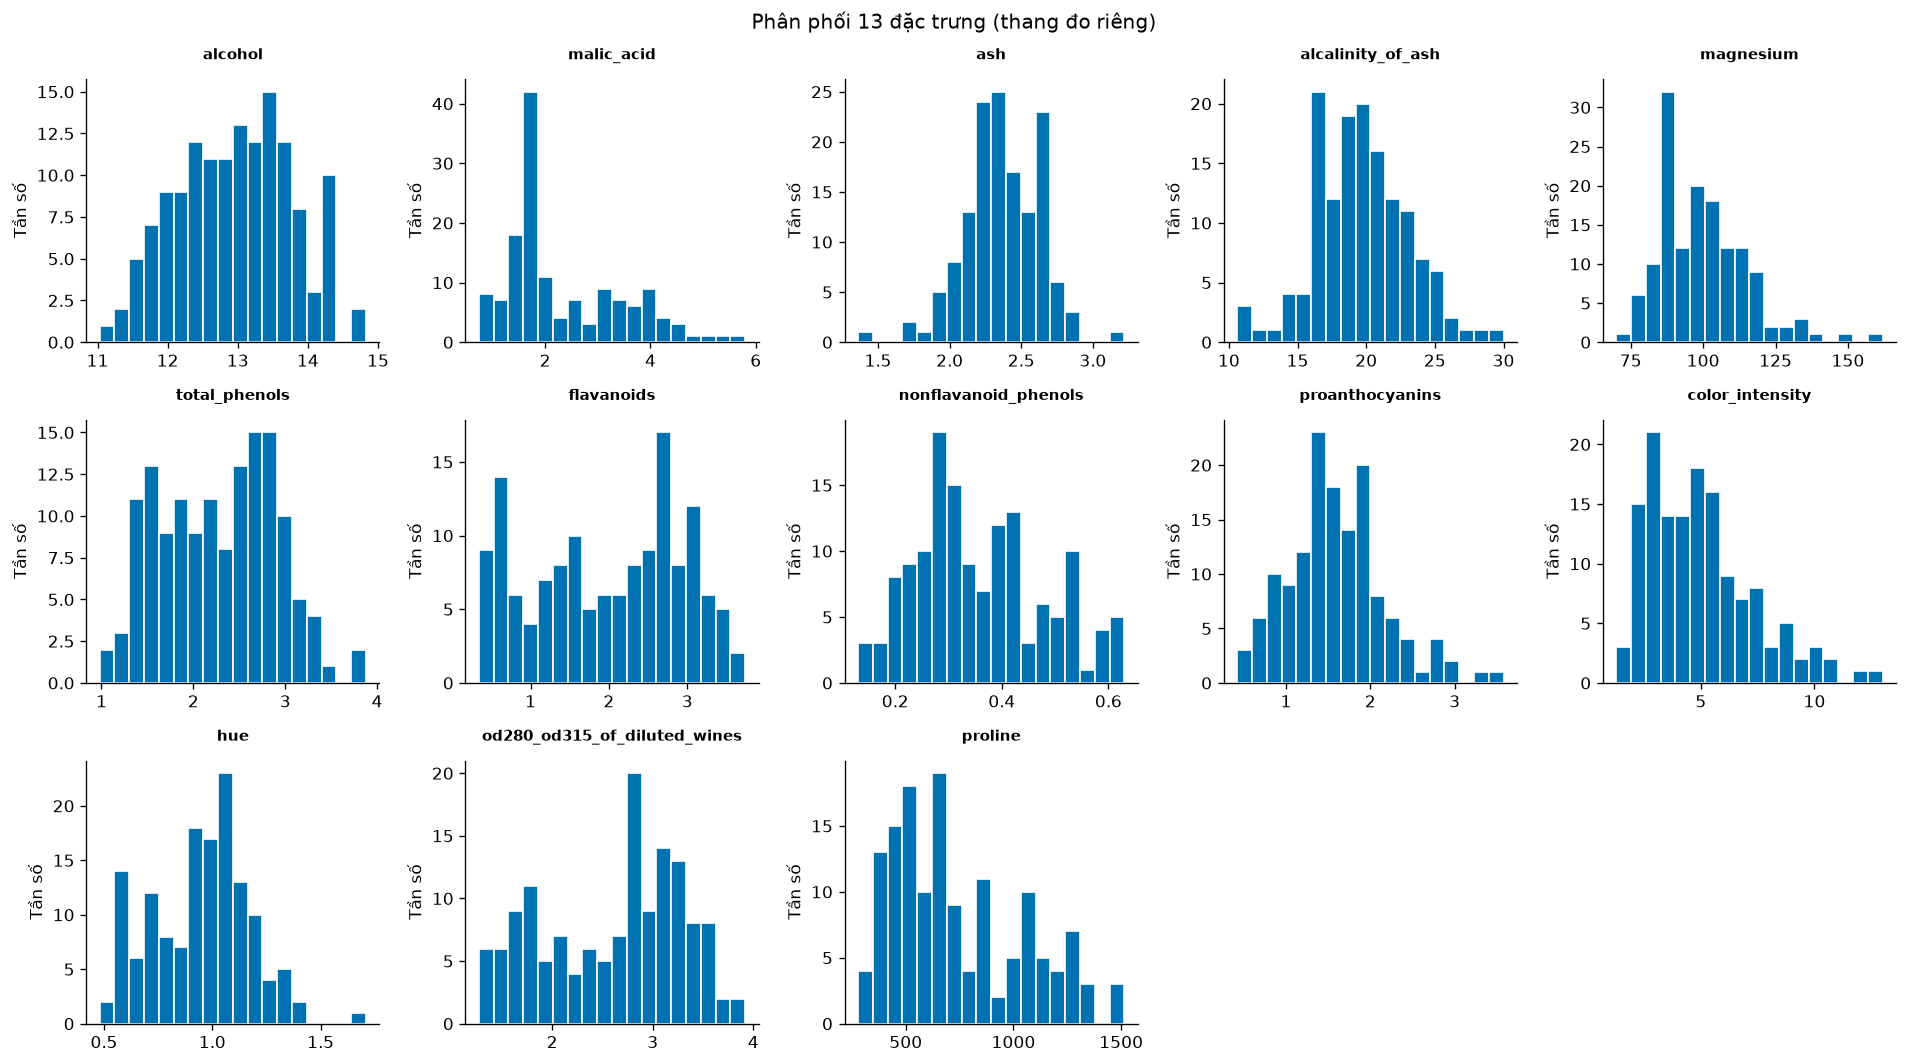

,Skewness (pandas)
magnesium,1.167
malic_acid,0.932
color_intensity,0.924
proline,0.687
proanthocyanins,0.552
nonflavanoid_phenols,0.391
alcalinity_of_ash,0.108
total_phenols,0.087
hue,0.064
alcohol,0.000


**Phân tích.** Biên độ quan sát lớn nhất thuộc **proline** (1237.000), nhỏ nhất thuộc **nonflavanoid_phenols** (0.500), trên các đơn vị đo gốc khác nhau. Đây là khác biệt về thang đo, không phải thứ hạng mức độ quan trọng. Ba thuộc tính có |skewness| lớn nhất là **magnesium: 1.167; malic_acid: 0.932; color_intensity: 0.924**. Giá trị dương biểu thị đuôi phân phối kéo dài về phía giá trị lớn; giá trị âm biểu thị hướng ngược lại. PCA ở phần sau sử dụng dữ liệu chuẩn hóa để hạn chế sự chi phối do thang đo.

WindowsPath('C:/Users/ASUS/Documents/code/thực hành/bài tập nhóm data mining/datasets/output/05_train_skewness.csv')

In [10]:
fig, axes = plt.subplots(3, 5, figsize=(16, 9))
for ax, col in zip(axes.flat, FEATURES):
    ax.hist(df_clean[col], bins=18, color="#0072B2", edgecolor="white")
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("Tần số")
for ax in axes.flat[len(FEATURES):]:
    ax.set_visible(False)
fig.suptitle("Phân phối 13 đặc trưng (thang đo riêng)")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "02_train_histograms.png", dpi=200, bbox_inches="tight")
plt.show()
skewness = df_clean[FEATURES].skew().sort_values(ascending=False)
display(skewness.rename("Skewness (pandas)").round(3).to_frame())

ranges = (df_clean[FEATURES].max() - df_clean[FEATURES].min()).sort_values(ascending=False)
skew_rank = skewness.reindex(skewness.abs().sort_values(ascending=False).index).head(3)
skew_text = "; ".join(f"{name}: {value:.3f}" for name, value in skew_rank.items())
display(Markdown(
    f"**Phân tích.** Biên độ quan sát lớn nhất thuộc **{ranges.index[0]}** ({ranges.iloc[0]:.3f}), "
    f"nhỏ nhất thuộc **{ranges.index[-1]}** ({ranges.iloc[-1]:.3f}), trên các đơn vị đo gốc khác nhau. "
    "Đây là khác biệt về thang đo, không phải thứ hạng mức độ quan trọng. "
    f"Ba thuộc tính có |skewness| lớn nhất là **{skew_text}**. "
    "Giá trị dương biểu thị đuôi phân phối kéo dài về phía giá trị lớn; giá trị âm biểu thị hướng ngược lại. "
    "PCA ở phần sau sử dụng dữ liệu chuẩn hóa để hạn chế sự chi phối do thang đo."
))
save_table(skewness.rename("skewness").to_frame(), "05_train_skewness.csv", index=True)

### 1.6. Khảo sát giá trị ngoại lai

Sử dụng ngưỡng Tukey: **[Q1 − 1,5 × IQR; Q3 + 1,5 × IQR]**. Báo cáo riêng số ô bị gắn cờ và số bản ghi có ít nhất một cờ. Boxplot Z-score chỉ phục vụ so sánh phân bố giữa các thuộc tính; không thay đổi dữ liệu nguồn.

**Nguyên tắc xử lý:** điểm ngoài ngưỡng là đối tượng cần xem xét, không mặc nhiên là lỗi. Chưa có thông tin xác minh lỗi đo/nhập liệu nên không loại dòng hoặc cắt ngọn giá trị. Các ngưỡng IQR được tính chỉ từ train và áp dụng nguyên vẹn cho test; diễn giải cùng phân bố theo lớp.

,Q1,Q3,IQR,Số giá trị bị gắn cờ
magnesium,88.000,107.750,19.750,3
alcalinity_of_ash,17.200,21.500,4.300,3
ash,2.200,2.560,0.360,2
color_intensity,3.058,6.182,3.125,2
proanthocyanins,1.250,1.950,0.700,2
hue,0.780,1.090,0.310,1
malic_acid,1.610,3.170,1.560,1
alcohol,12.370,13.560,1.190,0
total_phenols,1.705,2.800,1.095,0
nonflavanoid_phenols,0.270,0.430,0.160,0


Tổng số ô bị gắn cờ: 14
Số dòng có ít nhất một cờ: 11
Quyết định: giữ nguyên các dòng; không cắt ngọn hoặc xóa theo IQR.


C:\Users\ASUS\AppData\Local\Temp\ipykernel_13276\1073840797.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([z_plot[c] for c in FEATURES], vert=False, patch_artist=True,


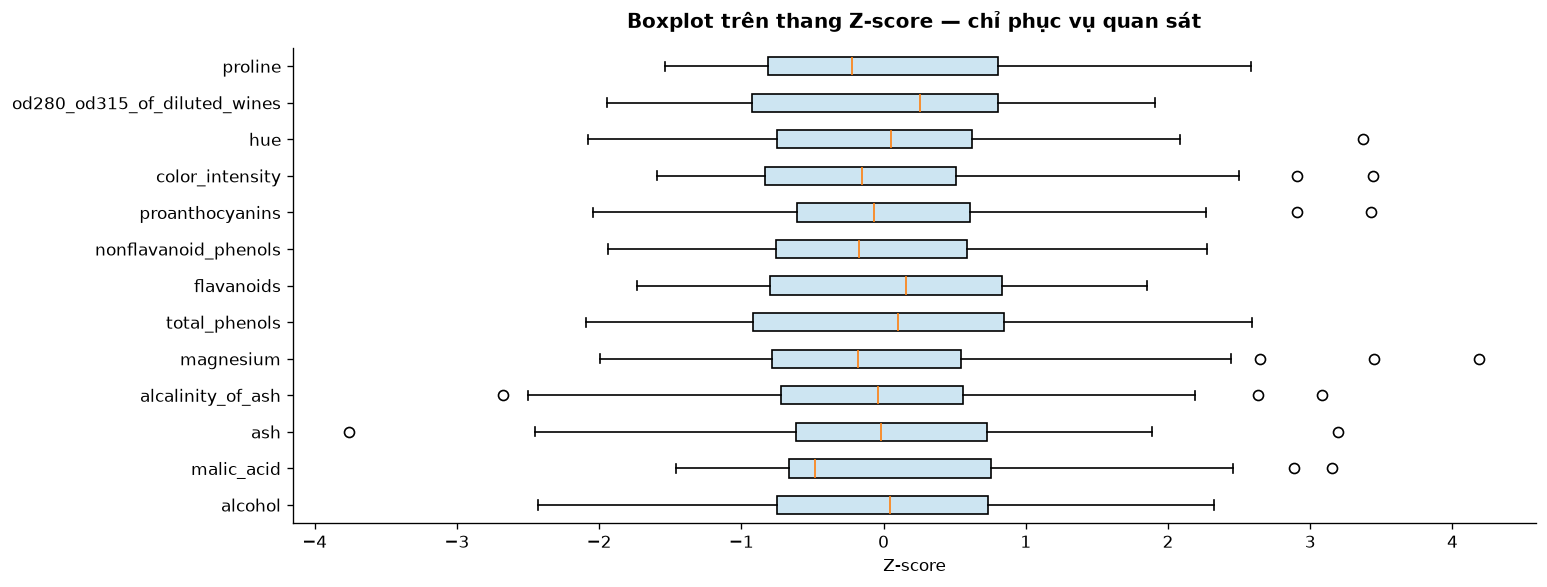

WindowsPath('C:/Users/ASUS/Documents/code/thực hành/bài tập nhóm data mining/datasets/output/06_train_zscore_for_boxplot.csv')

In [11]:
X = X_train.copy()
y = y_train.copy()
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
outlier_mask = X.lt(q1 - 1.5*iqr) | X.gt(q3 + 1.5*iqr)
outlier_summary = pd.DataFrame({"Q1": q1, "Q3": q3, "IQR": iqr,
                                "Số giá trị bị gắn cờ": outlier_mask.sum()})
display(outlier_summary.sort_values("Số giá trị bị gắn cờ", ascending=False).round(3))
print("Tổng số ô bị gắn cờ:", int(outlier_mask.to_numpy().sum()))
print("Số dòng có ít nhất một cờ:", int(outlier_mask.any(axis=1).sum()))
print("Quyết định: giữ nguyên các dòng; không cắt ngọn hoặc xóa theo IQR.")

z_plot = (X - X.mean()) / X.std(ddof=0)
fig, ax = plt.subplots(figsize=(13, 5))
ax.boxplot([z_plot[c] for c in FEATURES], vert=False, patch_artist=True,
           boxprops={"facecolor": "#CDE5F2"})
ax.set_yticks(range(1, len(FEATURES)+1), FEATURES)
ax.set(title="Boxplot trên thang Z-score — chỉ phục vụ quan sát", xlabel="Z-score")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "03_train_outlier_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()
# Test dùng ngưỡng IQR của train; chỉ gắn cờ, không loại hoặc sửa giá trị.
test_outlier_mask = X_test.lt(q1 - 1.5*iqr) | X_test.gt(q3 + 1.5*iqr)
save_table(outlier_summary, "06_train_iqr_summary.csv", index=True)
save_table(pd.DataFrame({"lower": q1 - 1.5*iqr, "upper": q3 + 1.5*iqr}), "06_iqr_train_bounds.csv", index=True)
save_table(outlier_mask.astype(int), "06_train_iqr_flags.csv")
save_table(test_outlier_mask.astype(int), "06_test_iqr_flags.csv")
save_table(X_train, "06_X_train_after_outlier_review.csv")
save_table(X_test, "06_X_test_after_outlier_review.csv")
save_table(z_plot, "06_train_zscore_for_boxplot.csv")

In [12]:
flagged_cells = int(outlier_mask.to_numpy().sum())
flagged_rows = int(outlier_mask.any(axis=1).sum())
flag_counts = outlier_mask.sum().sort_values(ascending=False)
flag_text = "; ".join(f"{name}: {int(value)}" for name, value in flag_counts.items() if value > 0)
display(Markdown(
    f"**Phân tích.** Quy tắc IQR gắn cờ **{flagged_cells} giá trị** trên "
    f"**{flagged_rows} bản ghi ({flagged_rows/len(df_clean):.2%})**. "
    f"Phân bố cờ theo thuộc tính: {flag_text or 'không có'}. "
    "Một bản ghi có thể được gắn cờ ở nhiều thuộc tính nên hai số lượng này không tương đương. "
    "Các điểm được giữ lại; kết quả PCA cần được xem xét với lưu ý rằng StandardScaler không loại bỏ ảnh hưởng của ngoại lai."
))

**Phân tích.** Quy tắc IQR gắn cờ **14 giá trị** trên **11 bản ghi (7.75%)**. Phân bố cờ theo thuộc tính: magnesium: 3; alcalinity_of_ash: 3; ash: 2; color_intensity: 2; proanthocyanins: 2; hue: 1; malic_acid: 1. Một bản ghi có thể được gắn cờ ở nhiều thuộc tính nên hai số lượng này không tương đương. Các điểm được giữ lại; kết quả PCA cần được xem xét với lưu ý rằng StandardScaler không loại bỏ ảnh hưởng của ngoại lai.

### 1.7. Mối liên hệ giữa các thuộc tính và phân bố theo lớp

Ma trận Pearson mô tả mức độ liên hệ tuyến tính giữa các thuộc tính liên tục. Mỗi cặp chỉ xuất hiện một lần trong bảng xếp hạng |r|. Tương quan không chứng minh quan hệ nhân quả và không đủ để tự động loại một biến.

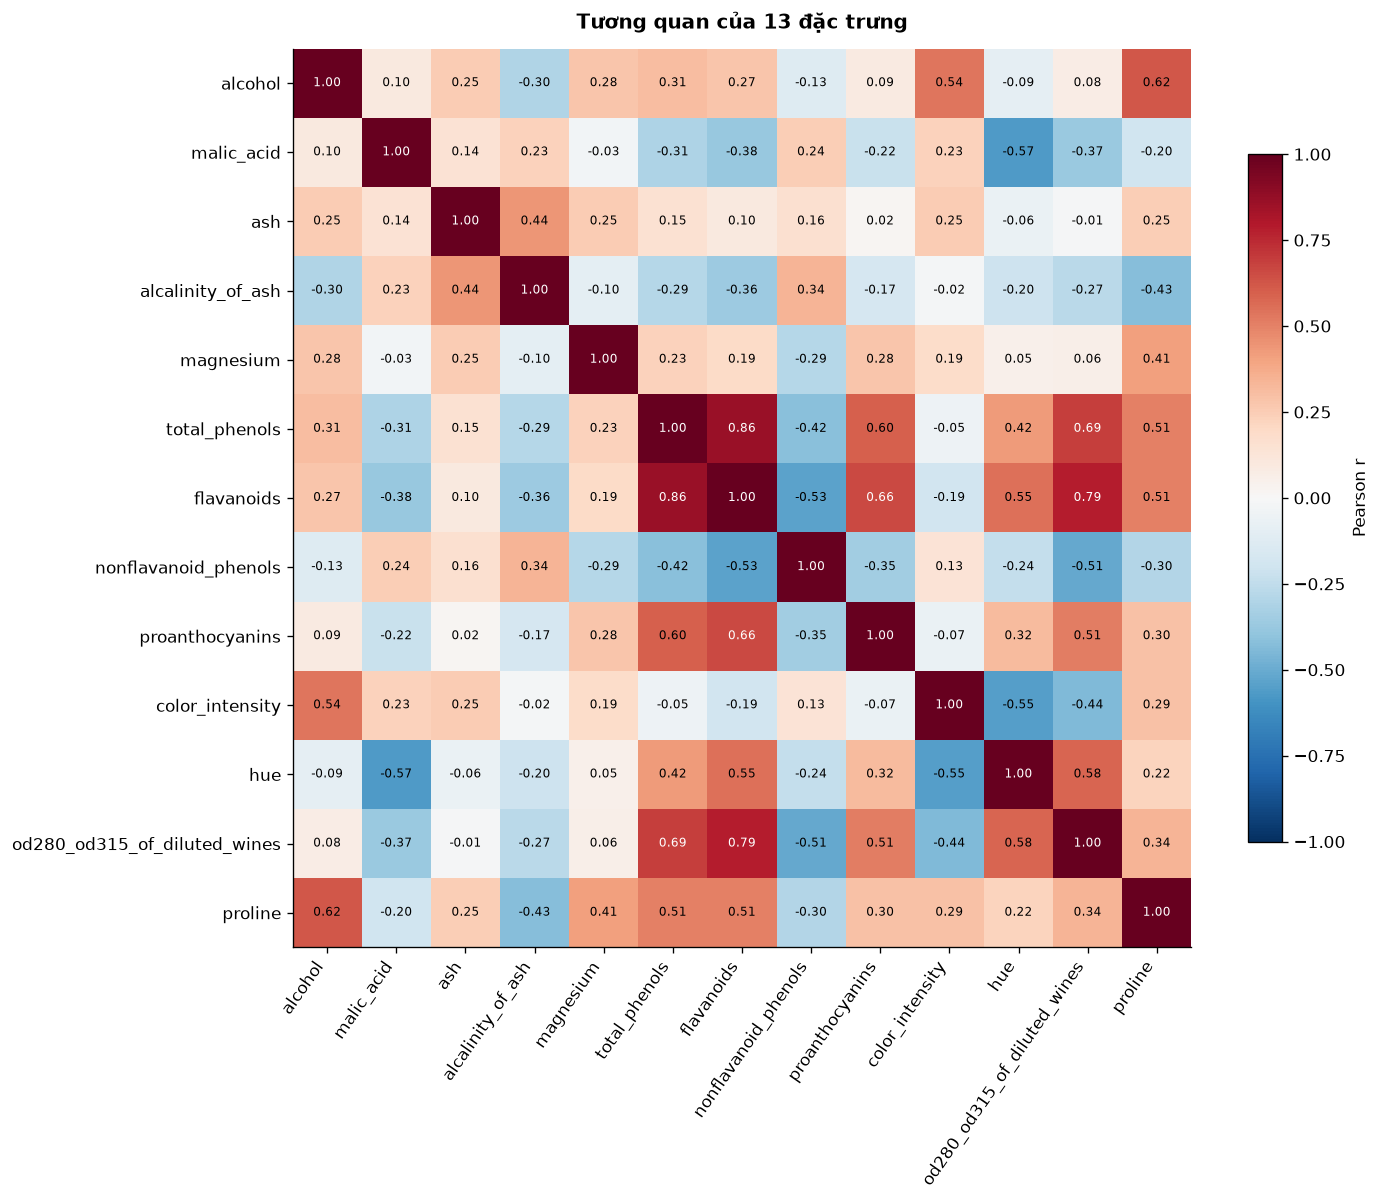

,Đặc trưng A,Đặc trưng B,r
50,total_phenols,flavanoids,0.861
61,flavanoids,od280_od315_of_diluted_wines,0.786
55,total_phenols,od280_od315_of_diluted_wines,0.695
58,flavanoids,proanthocyanins,0.657
11,alcohol,proline,0.621


WindowsPath('C:/Users/ASUS/Documents/code/thực hành/bài tập nhóm data mining/datasets/output/07_train_top_correlations.csv')

In [13]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=55, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i,j]) > 0.65 else "black")
fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson r")
ax.set_title("Tương quan của 13 đặc trưng")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "04_train_correlation.png", dpi=200, bbox_inches="tight")
plt.show()
pairs = [(FEATURES[i], FEATURES[j], corr.iloc[i,j])
         for i in range(len(FEATURES)) for j in range(i+1, len(FEATURES))]
top_corr = pd.DataFrame(pairs, columns=["Đặc trưng A", "Đặc trưng B", "r"])
top_corr = top_corr.iloc[np.argsort(-top_corr["r"].abs().to_numpy())].head(5)
display(top_corr.round(3))
save_table(corr, "07_train_correlation.csv", index=True)
save_table(top_corr, "07_train_top_correlations.csv")

In [14]:
strongest = top_corr.iloc[0]
display(Markdown(
    f"**Phân tích tương quan.** Cặp có |r| lớn nhất là **{strongest['Đặc trưng A']}** và "
    f"**{strongest['Đặc trưng B']}**, với **r = {strongest['r']:.3f}** "
    f"({'cùng chiều' if strongest['r'] > 0 else 'ngược chiều'}). "
    "Sự liên hệ giữa các thuộc tính là cơ sở khảo sát khả năng biểu diễn thông tin bằng các thành phần chính. "
    "Chưa loại thuộc tính dựa riêng trên ma trận tương quan."
))

**Phân tích tương quan.** Cặp có |r| lớn nhất là **total_phenols** và **flavanoids**, với **r = 0.861** (cùng chiều). Sự liên hệ giữa các thuộc tính là cơ sở khảo sát khả năng biểu diễn thông tin bằng các thành phần chính. Chưa loại thuộc tính dựa riêng trên ma trận tương quan.

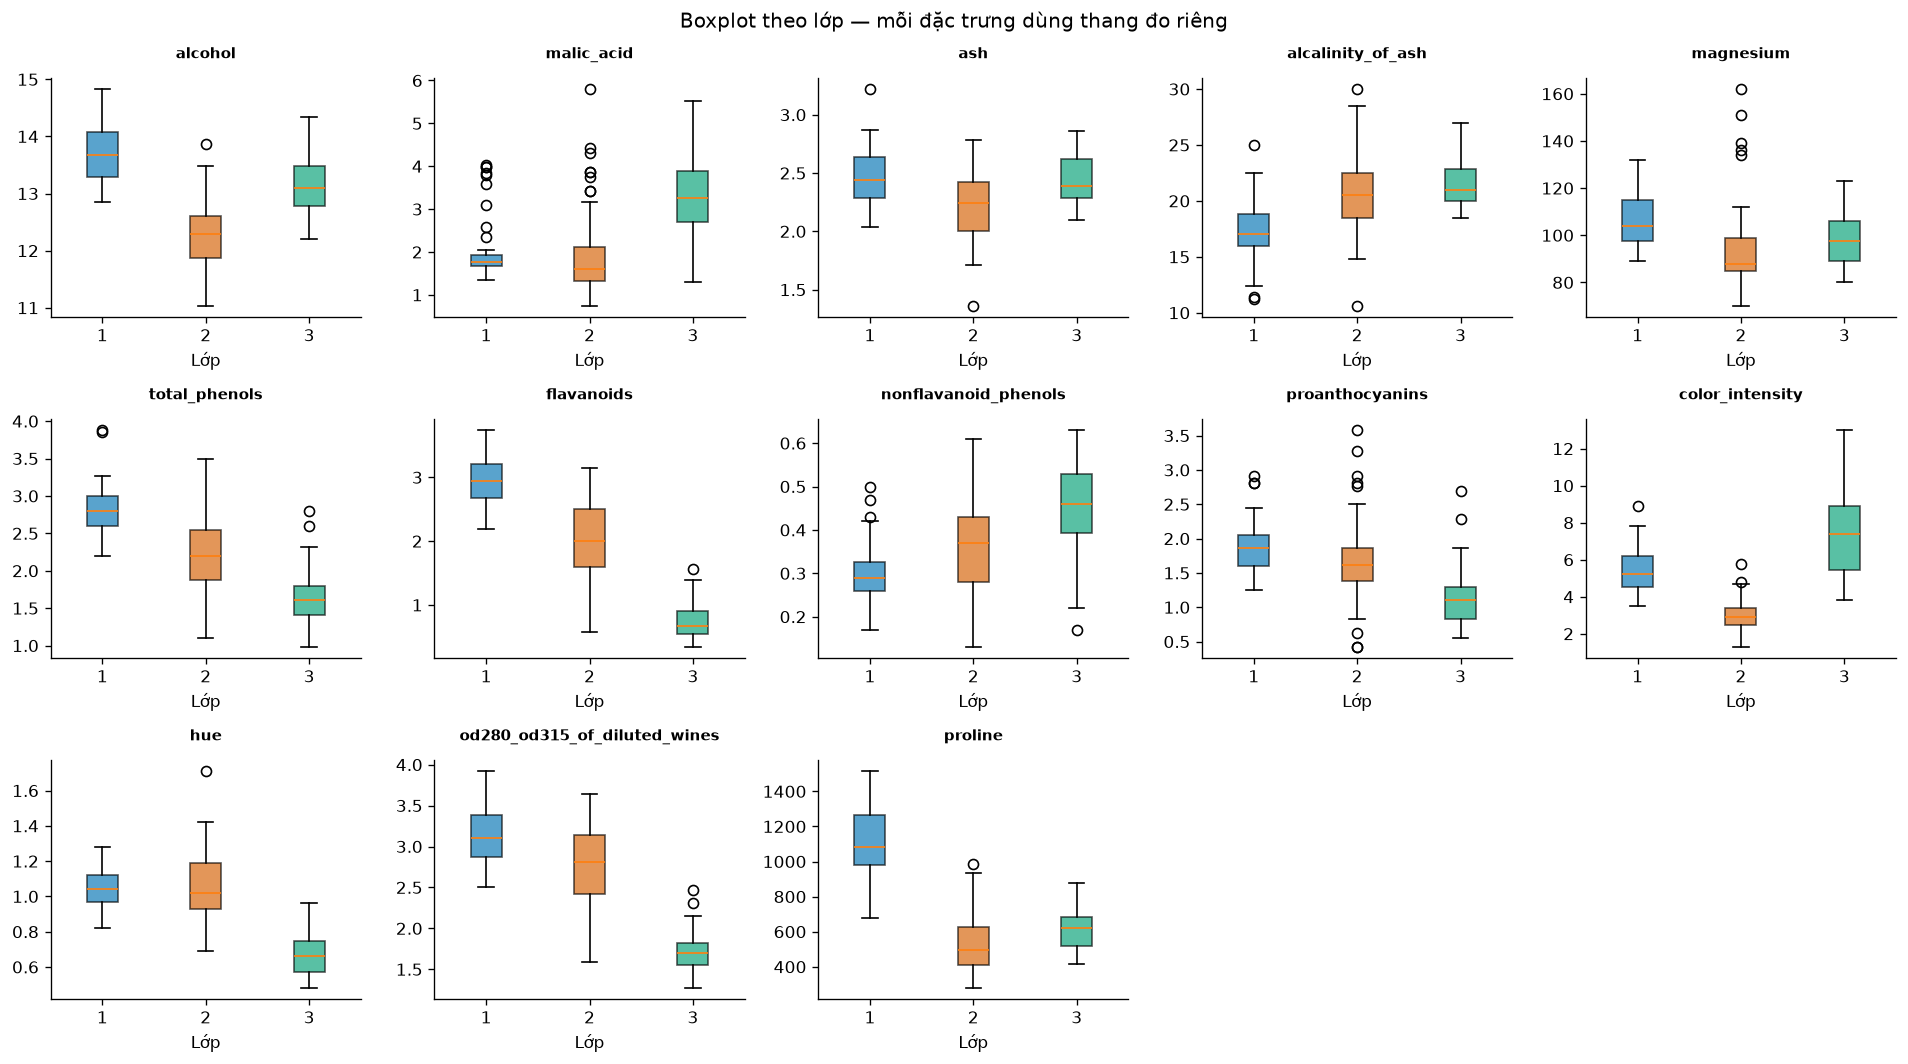

In [15]:
fig, axes = plt.subplots(3, 5, figsize=(16, 9))
classes = sorted(y.unique())
for ax, col in zip(axes.flat, FEATURES):
    bp = ax.boxplot([X.loc[y == k, col] for k in classes], patch_artist=True)
    for box, k in zip(bp["boxes"], classes):
        box.set_facecolor(CLASS_COLORS[k])
        box.set_alpha(0.65)
    ax.set_xticks(range(1, len(classes)+1), [str(k) for k in classes])
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("Lớp")
for ax in axes.flat[len(FEATURES):]:
    ax.set_visible(False)
fig.suptitle("Boxplot theo lớp — mỗi đặc trưng dùng thang đo riêng")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "05_train_boxplot_by_class.png", dpi=200, bbox_inches="tight")
plt.show()

**Hướng diễn giải boxplot.** So sánh trung vị, độ rộng khoảng tứ phân vị và phần chồng lấn giữa các lớp trong từng thuộc tính. Khác biệt vị trí phân bố cho thấy khả năng phân biệt về mặt mô tả; không được đồng nhất với độ chính xác phân loại. Không so sánh độ cao hộp giữa các thuộc tính có đơn vị khác nhau.

## 2. Tạo dữ liệu mới và trực quan hóa
### 2.1. Chọn thuộc tính liên tục và chuẩn hóa

Chọn các đại lượng đo hóa học làm đầu vào X; tách nhãn y. Giữ Proline vì đây là thuộc tính đo lường, không phải cột dư. Chuẩn hóa theo công thức **z = (x − μ) / σ** để mỗi thuộc tính có trung bình xấp xỉ 0 và độ lệch chuẩn xấp xỉ 1.

Train/test đã được chia trước tiền xử lý. StandardScaler chỉ fit trên X_train; X_test chỉ được transform với trung bình và độ lệch chuẩn của train. PCA cũng chỉ fit trên train và transform test. Mỗi kết quả được lưu riêng. Khi chạy cross-validation sau này, các bước fit vẫn phải được thực hiện lại trong từng fold của Pipeline.

In [16]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)
X_scaled = X_train_scaled  # Các phân tích PCA hiện có chỉ dùng train để fit.

scale_check = pd.DataFrame({"Mean sau chuẩn hóa": X_train_scaled.mean(),
                           "Std sau chuẩn hóa (ddof=0)": X_train_scaled.std(ddof=0)})
display(scale_check.round(6))
assert TARGET not in X_train_scaled.columns and TARGET not in X_test_scaled.columns
assert np.isfinite(X_train_scaled.to_numpy()).all() and np.isfinite(X_test_scaled.to_numpy()).all()
assert np.allclose(X_train_scaled.mean(), 0, atol=1e-10)
assert np.allclose(X_train_scaled.std(ddof=0), 1, atol=1e-10)

# x_train/x_test là các đặc trưng chuẩn hóa, không chứa nhãn.
save_table(X_train_scaled, "x_train.csv")
save_table(X_test_scaled, "x_test.csv")
save_table(pd.DataFrame({"mean": scaler.mean_, "scale": scaler.scale_}, index=FEATURES),
           "08_scaler_train_parameters.csv", index=True)
save_table(scale_check, "08_train_scaling_check.csv", index=True)
print("Đã lưu x_train.csv và x_test.csv; nhãn nằm riêng trong y_train.csv, y_test.csv.")

,Mean sau chuẩn hóa,Std sau chuẩn hóa (ddof=0)
alcohol,0.0,1.0
malic_acid,0.0,1.0
ash,-0.0,1.0
alcalinity_of_ash,0.0,1.0
magnesium,0.0,1.0
total_phenols,-0.0,1.0
flavanoids,-0.0,1.0
nonflavanoid_phenols,-0.0,1.0
proanthocyanins,0.0,1.0
color_intensity,0.0,1.0


Đã lưu x_train.csv và x_test.csv; nhãn nằm riêng trong y_train.csv, y_test.csv.


### 2.2. Phương sai giải thích và giới hạn của biểu diễn 2D

PCA xác định các trục trực giao theo phương sai của dữ liệu đã chuẩn hóa, không sử dụng nhãn. Báo cáo phương sai từng thành phần và phương sai tích lũy để lượng hóa thông tin được giữ lại. Ngưỡng 95% là thông tin bổ sung; yêu cầu trực quan hóa vẫn sử dụng hai thành phần đầu.

Tỷ lệ phương sai báo cáo được tính trên train. Test không tham gia xác định các trục hoặc số thành phần chính.

,PC,Phương sai (%),Tích lũy (%)
0,1,35.79,35.79
1,2,19.27,55.06
2,3,11.02,66.08
3,4,7.27,73.35
4,5,6.72,80.08
5,6,5.13,85.21
6,7,4.38,89.59
7,8,2.50,92.09
8,9,2.28,94.37
9,10,1.88,96.24


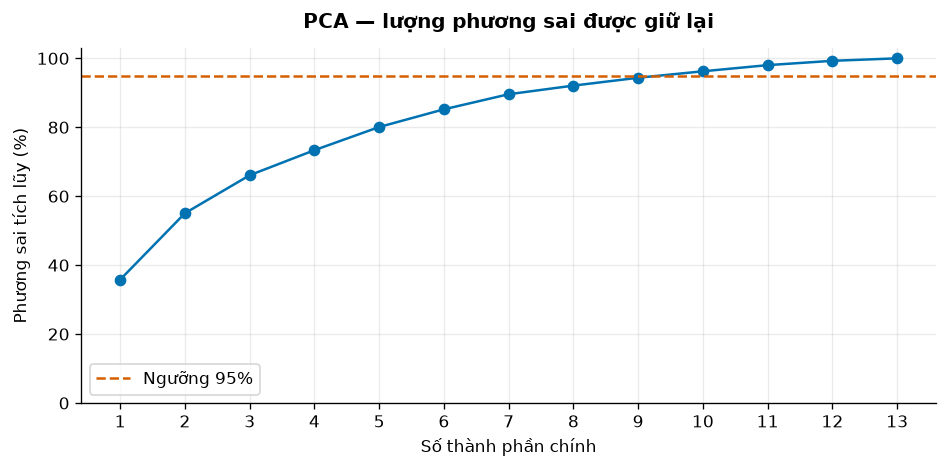

Hai PC đầu giữ 55.06% phương sai.
Cần 10 PC để giữ ít nhất 95% (thực tế: 96.24%).


WindowsPath('C:/Users/ASUS/Documents/code/thực hành/bài tập nhóm data mining/datasets/output/09_X_test_pca95.csv')

In [17]:
pca_full = PCA(svd_solver="full")
pca_full.fit(X_scaled)
ratio = pca_full.explained_variance_ratio_
cumulative = np.cumsum(ratio)
n95 = int(np.searchsorted(cumulative, 0.95) + 1)
variance_table = pd.DataFrame({"PC": np.arange(1, len(ratio)+1),
                               "Phương sai (%)": ratio*100,
                               "Tích lũy (%)": cumulative*100})
display(variance_table.round(2))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(variance_table["PC"], cumulative*100, "o-", color="#0072B2")
ax.axhline(95, color="#D55E00", linestyle="--", label="Ngưỡng 95%")
ax.set(xlabel="Số thành phần chính", ylabel="Phương sai tích lũy (%)",
       title="PCA — lượng phương sai được giữ lại", xticks=range(1, len(ratio)+1), ylim=(0,103))
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "06_train_pca_variance.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"Hai PC đầu giữ {cumulative[1]:.2%} phương sai.")
print(f"Cần {n95} PC để giữ ít nhất 95% (thực tế: {cumulative[n95-1]:.2%}).")
save_table(variance_table, "09_pca_train_explained_variance.csv")
all_pc_names = [f"PC{i+1}" for i in range(len(ratio))]
train_all_pc = pd.DataFrame(pca_full.transform(X_train_scaled), columns=all_pc_names, index=X_train.index)
test_all_pc = pd.DataFrame(pca_full.transform(X_test_scaled), columns=all_pc_names, index=X_test.index)
save_table(train_all_pc, "09_X_train_pca_all.csv")
save_table(test_all_pc, "09_X_test_pca_all.csv")
save_table(train_all_pc.iloc[:, :n95], "09_X_train_pca95.csv")
save_table(test_all_pc.iloc[:, :n95], "09_X_test_pca95.csv")

### 2.3. Biểu diễn PCA hai chiều theo nhãn

Tạo bảng mới gồm PC1, PC2 và nhãn để diễn giải. Các nhãn được gắn lại sau phép biến đổi, không tham gia fit PCA. Biểu đồ sử dụng màu lớp thống nhất, hiển thị tỷ lệ phương sai ngay trên từng trục.

Biểu đồ giữ nguyên bố cục và hiển thị train. Dữ liệu test được chiếu bằng cùng PCA và lưu riêng, không gộp với train.

,PC1,PC2,class
36,1.472343,0.734251,1
30,2.649709,1.230211,1
26,1.888788,0.792472,1
12,2.211159,0.753458,1
148,-2.817571,1.645688,3
171,-3.731651,0.943745,3
69,2.003185,-1.488667,2
150,-2.287491,2.379894,3
53,2.344948,1.926216,1
8,2.583804,1.010108,1


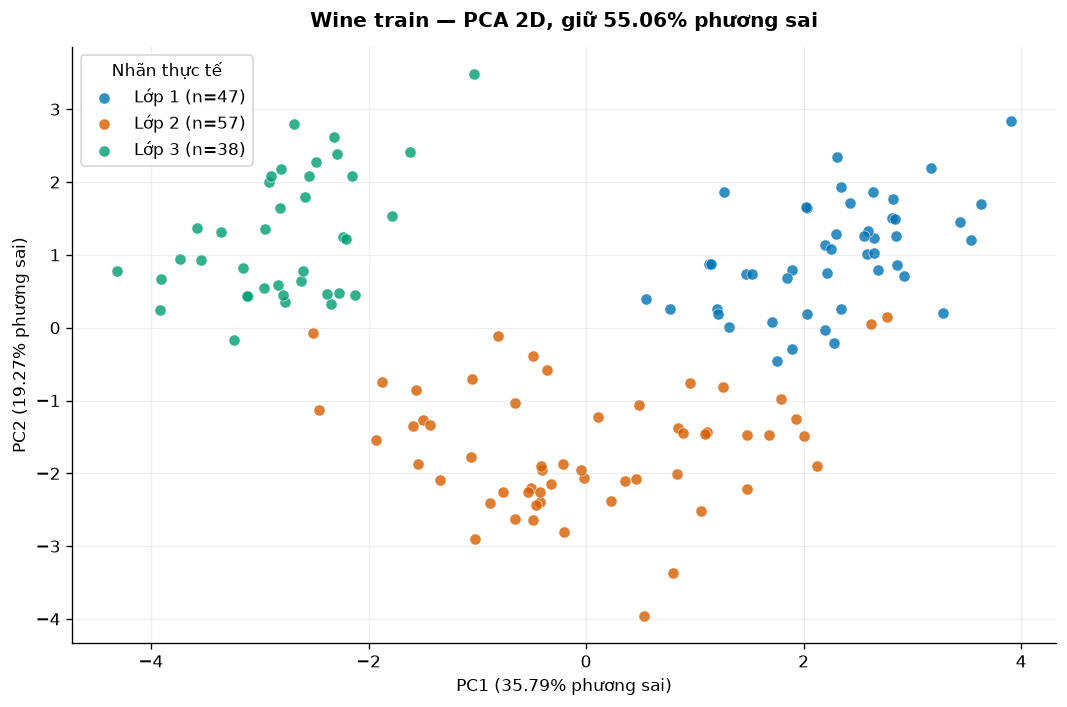

**Đánh giá phép chiếu.** PC1 giải thích **35.79%**, PC2 giải thích **19.27%**, tổng cộng **55.06%** phương sai. **44.94%** phương sai còn lại nằm ở các chiều không được thể hiện trên hình. Vì vậy, các điểm gần nhau trong 2D không nhất thiết gần nhau tương ứng trong toàn bộ không gian đặc trưng. Màu thể hiện nhãn quan sát, không phải cụm do PCA tìm ra. PCA tối đa hóa phương sai thay vì tối ưu độ tách lớp; không suy ra hiệu năng phân loại từ hình chiếu.

In [18]:
pca_2d = PCA(n_components=2, svd_solver="full")
coordinates = pca_2d.fit_transform(X_train_scaled)
test_coordinates = pca_2d.transform(X_test_scaled)
X_train_pca = pd.DataFrame(coordinates, columns=["PC1", "PC2"], index=X_train.index)
X_test_pca = pd.DataFrame(test_coordinates, columns=["PC1", "PC2"], index=X_test.index)
save_table(X_train_pca, "10_X_train_pca2d.csv")
save_table(X_test_pca, "10_X_test_pca2d.csv")
train_pca_labeled = X_train_pca.assign(**{TARGET: y_train})
test_pca_labeled = X_test_pca.assign(**{TARGET: y_test})
save_table(train_pca_labeled, "10_train_pca2d_with_label.csv")
save_table(test_pca_labeled, "10_test_pca2d_with_label.csv")
df_pca_2d = pd.DataFrame(coordinates, columns=["PC1", "PC2"], index=X.index)
df_pca_2d["class"] = y
display(df_pca_2d.head(10))
fig, ax = plt.subplots(figsize=(9, 6))
for k in classes:
    group = df_pca_2d.loc[df_pca_2d["class"] == k]
    ax.scatter(group["PC1"], group["PC2"], color=CLASS_COLORS[k],
               label=f"Lớp {k} (n={len(group)})", s=45, alpha=0.8,
               edgecolors="white", linewidths=0.4)
v1, v2 = pca_2d.explained_variance_ratio_
ax.set(xlabel=f"PC1 ({v1:.2%} phương sai)", ylabel=f"PC2 ({v2:.2%} phương sai)",
       title=f"Wine train — PCA 2D, giữ {v1+v2:.2%} phương sai")
ax.legend(title="Nhãn thực tế")
ax.grid(alpha=0.2)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "07_train_pca2d.png", dpi=200, bbox_inches="tight")
plt.show()

display(Markdown(
    f"**Đánh giá phép chiếu.** PC1 giải thích **{v1:.2%}**, PC2 giải thích **{v2:.2%}**, "
    f"tổng cộng **{v1+v2:.2%}** phương sai. **{1-v1-v2:.2%}** phương sai còn lại nằm ở các chiều "
    "không được thể hiện trên hình. Vì vậy, các điểm gần nhau trong 2D không nhất thiết gần nhau tương ứng "
    "trong toàn bộ không gian đặc trưng. Màu thể hiện nhãn quan sát, không phải cụm do PCA tìm ra. "
    "PCA tối đa hóa phương sai thay vì tối ưu độ tách lớp; không suy ra hiệu năng phân loại từ hình chiếu."
))

### 2.4. Diễn giải các thành phần chính

Bảng dưới trình bày hệ số của các thuộc tính trong PC1 và PC2 trên dữ liệu chuẩn hóa. Giá trị tuyệt đối lớn biểu thị trọng số lớn trong tổ hợp tuyến tính; không phải độ quan trọng của một mô hình phân loại. Dấu toàn bộ một trục PCA có thể đảo mà không làm thay đổi cấu trúc phép chiếu.

In [19]:
coefficients = pd.DataFrame(pca_2d.components_.T, index=FEATURES, columns=["PC1", "PC2"])
display(coefficients.round(4))
for component in coefficients.columns:
    ordered = coefficients[component].abs().nlargest(3).index
    terms = "; ".join(f"{name} ({coefficients.loc[name, component]:+.3f})" for name in ordered)
    display(Markdown(f"**{component}:** ba thuộc tính có hệ số lớn nhất về trị tuyệt đối: {terms}."))
save_table(coefficients, "10_pca2d_train_coefficients.csv", index=True)

,PC1,PC2
alcohol,0.1444,0.4869
malic_acid,-0.2337,0.2229
ash,0.0071,0.3116
alcalinity_of_ash,-0.2236,-0.0390
magnesium,0.1518,0.2964
total_phenols,0.3944,0.0763
flavanoids,0.4295,-0.0025
nonflavanoid_phenols,-0.2914,0.0208
proanthocyanins,0.3133,0.0109
color_intensity,-0.0964,0.5244


**PC1:** ba thuộc tính có hệ số lớn nhất về trị tuyệt đối: flavanoids (+0.430); total_phenols (+0.394); od280_od315_of_diluted_wines (+0.383).

**PC2:** ba thuộc tính có hệ số lớn nhất về trị tuyệt đối: color_intensity (+0.524); alcohol (+0.487); proline (+0.358).

WindowsPath('C:/Users/ASUS/Documents/code/thực hành/bài tập nhóm data mining/datasets/output/10_pca2d_train_coefficients.csv')

### 2.5. Dữ liệu đầu ra

Mỗi bước đã lưu ngay vào tệp CSV riêng trong `datasets/output`. `train_data.csv` và `test_data.csv` là dữ liệu sau chia, trước xử lý; `x_train.csv` và `x_test.csv` là đặc trưng sau chuẩn hóa, không chứa nhãn. Nhãn nằm trong `y_train.csv`, `y_test.csv`; thứ tự dòng khớp với các tệp X của cùng tập sau làm sạch. Các tệp PCA được lưu riêng, không ghi đè các tệp chuẩn hóa. Bảng bên dưới liệt kê đầy đủ các tệp tạo trong lần chạy.

Biểu đồ PNG được lưu vào thư mục `output` ở gốc dự án. Không tạo thư mục `wine_preprocessing_output` mới và không gộp train/test vào một tệp.

In [20]:
assert len(X_train_scaled) == len(y_train) == len(X_train_pca)
assert len(X_test_scaled) == len(y_test) == len(X_test_pca)
assert X_train_scaled.index.equals(y_train.index)
assert X_test_scaled.index.equals(y_test.index)
assert np.isfinite(test_coordinates).all()

manifest = pd.DataFrame(saved_files).drop_duplicates("Tệp", keep="last").reset_index(drop=True)
display(manifest)
manifest.to_csv(OUTPUT_DIR / "output_manifest.csv", index=False, encoding="utf-8-sig")
print("CSV:", OUTPUT_DIR)
print("Biểu đồ PNG:", FIGURE_DIR)

,Tệp,Số dòng,Thư mục
0,00_wine_from_xlsx.csv,178,datasets/output
1,train_data.csv,142,datasets/output
2,test_data.csv,36,datasets/output
3,01_split_membership.csv,178,datasets/output
4,02_train_columns_cleaned.csv,142,datasets/output
5,02_test_columns_cleaned.csv,36,datasets/output
6,03_train_dtypes.csv,14,datasets/output
7,03_train_class_counts.csv,3,datasets/output
8,03_train_quality.csv,14,datasets/output
9,04_train_clean.csv,142,datasets/output


CSV: C:\Users\ASUS\Documents\code\thực hành\bài tập nhóm data mining\datasets\output
Biểu đồ PNG: C:\Users\ASUS\Documents\code\thực hành\bài tập nhóm data mining\datasets\output


## Kết luận phân tích

Tóm tắt dưới đây được sinh từ kết quả xử lý hiện tại. Mọi thay đổi về tệp nguồn cần được phản ánh bằng cách chạy lại toàn bộ notebook.

In [21]:
summary = f"""
| Nội dung | Kết quả |
|---|---|
| Quy mô train dùng phân tích | {len(df_clean):,} mẫu × {len(FEATURES)} đặc trưng; {y.nunique()} lớp |
| Giá trị thiếu / không phải số / vô hạn | {int(quality['Thiếu'].sum())} / {int(quality['Không phải số'].sum())} / {int(quality['Vô hạn'].sum())} |
| Quy mô test sau làm sạch | {len(test_clean):,} mẫu |
| Bản ghi trùng đã loại (train / test) | {duplicate_count} / {test_duplicate_count} |
| Bản ghi có cờ IQR | {flagged_rows} ({flagged_rows/len(df_clean):.2%}); giữ nguyên để phân tích |
| Phương sai giữ lại trong 2D | {v1+v2:.2%} |
| Phương sai ngoài biểu diễn 2D | {1-v1-v2:.2%} |
| Số PC đạt ít nhất 95% phương sai | {n95} ({cumulative[n95-1]:.2%}) |

**Kết luận.** Quy trình đã chia train/test trước xử lý, fit scaler và PCA chỉ trên train, lưu riêng kết quả từng bước, xác nhận cấu trúc dữ liệu, báo cáo thống kê thuộc tính và phân bố nhãn, khảo sát chất lượng và tạo biểu diễn PCA hai chiều. Chuẩn hóa xử lý chênh lệch thang đo, còn bảng hệ số giúp giải thích vai trò của các thuộc tính trong hai trục chính. Hình chiếu chỉ thể hiện một phần phương sai; cần giữ bảng đặc trưng gốc khi thực hiện các phân tích tiếp theo. Không loại thuộc tính hoặc bản ghi chỉ dựa vào tương quan, cờ IQR hay vị trí điểm trên hình PCA.
"""
display(Markdown(summary))


| Nội dung | Kết quả |
|---|---|
| Quy mô train dùng phân tích | 142 mẫu × 13 đặc trưng; 3 lớp |
| Giá trị thiếu / không phải số / vô hạn | 0 / 0 / 0 |
| Quy mô test sau làm sạch | 36 mẫu |
| Bản ghi trùng đã loại (train / test) | 0 / 0 |
| Bản ghi có cờ IQR | 11 (7.75%); giữ nguyên để phân tích |
| Phương sai giữ lại trong 2D | 55.06% |
| Phương sai ngoài biểu diễn 2D | 44.94% |
| Số PC đạt ít nhất 95% phương sai | 10 (96.24%) |

**Kết luận.** Quy trình đã chia train/test trước xử lý, fit scaler và PCA chỉ trên train, lưu riêng kết quả từng bước, xác nhận cấu trúc dữ liệu, báo cáo thống kê thuộc tính và phân bố nhãn, khảo sát chất lượng và tạo biểu diễn PCA hai chiều. Chuẩn hóa xử lý chênh lệch thang đo, còn bảng hệ số giúp giải thích vai trò của các thuộc tính trong hai trục chính. Hình chiếu chỉ thể hiện một phần phương sai; cần giữ bảng đặc trưng gốc khi thực hiện các phân tích tiếp theo. Không loại thuộc tính hoặc bản ghi chỉ dựa vào tương quan, cờ IQR hay vị trí điểm trên hình PCA.


## 3. Huấn luyện mô hình phân loại — KNN, Gaussian Naive Bayes, Random Forest

Ba mô hình được huấn luyện trên 142 mẫu train với 13 đặc trưng. Tập test 36 mẫu được giữ riêng. Phân tích sử dụng F1-macro để đánh giá đồng đều ba lớp và xếp hạng mô hình.

Tên và thứ tự đặc trưng được đọc từ dữ liệu. Bảng dữ liệu đầy đủ dùng để kiểm tra đặc trưng và nhãn khớp nhau theo từng dòng. Mở notebook trong thư mục dự án hoặc đặt đường dẫn dự án trong `PROJECT_ROOT`.

In [22]:
# Đọc và kiểm tra dữ liệu
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, make_scorer, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = ""  # Ví dụ r"D:\k1_nam3\data_mining\data_mining"
start = Path(PROJECT_ROOT or Path.cwd()).expanduser().resolve()
data_dir = next(
    (root / "datasets" / "output" for root in (start, *start.parents)
     if (root / "datasets" / "output" / "05_X_train_raw.csv").is_file()),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Không tìm thấy dữ liệu train. Kiểm tra PROJECT_ROOT.")

X = pd.read_csv(data_dir / "05_X_train_raw.csv")
labels = pd.read_csv(data_dir / "y_train.csv")
reference = pd.read_csv(data_dir / "04_train_clean.csv")
if labels.columns.tolist() != ["class"] or "class" not in reference.columns:
    raise ValueError("Tệp nhãn phải có một cột class; bảng đối chiếu phải có class.")
y = labels["class"]
reference_X = reference.drop(columns="class")
if X.shape != (142, 13) or X.columns.tolist() != reference_X.columns.tolist():
    raise ValueError("Cần đúng 142 dòng và 13 đặc trưng, theo thứ tự của bảng đối chiếu.")
if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes):
    raise ValueError("Mọi đặc trưng phải có kiểu số.")
if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("Có đặc trưng thiếu hoặc vô hạn.")
if y.value_counts().to_dict() != {1: 47, 2: 57, 3: 38}:
    raise ValueError("Nhãn train phải có 47, 57 và 38 mẫu ở các lớp 1, 2, 3.")
if not X.equals(reference_X) or not y.equals(reference["class"]):
    raise ValueError("Đặc trưng hoặc nhãn không khớp từng dòng với 04_train_clean.csv.")

print(f"Train hợp lệ: {X.shape[0]} mẫu × {X.shape[1]} đặc trưng.")
print("Số mẫu theo lớp:", y.value_counts().sort_index().to_dict())

Train hợp lệ: 142 mẫu × 13 đặc trưng.
Số mẫu theo lớp: {1: 47, 2: 57, 3: 38}


## Phương pháp cross-validation

Dữ liệu train có 142 mẫu, gồm 47, 57 và 38 mẫu ở ba lớp. StratifiedKFold giữ tỷ lệ lớp gần bằng nhau. Mười fold theo yêu cầu bài tập, mỗi outer validation có khoảng 14–15 mẫu. Seed 42 cố định cách xáo trộn để tái lập.

Nested CV có vòng trong và vòng ngoài. Trong mỗi outer fold, chín phần dùng huấn luyện, một phần giữ làm validation. GridSearchCV chia outer-train thành inner 10-fold, thử lưới tham số và chọn cấu hình có F1-macro trung bình cao nhất. Cấu hình đó dự đoán outer validation chưa tham gia chọn tham số. Sau mười vòng, mọi mẫu train đều có dự đoán ngoài fold. Điểm outer CV đánh giá quy trình chọn tham số; GridSearch riêng trên toàn bộ train chọn cấu hình cuối để bàn giao.

F1-macro lấy trung bình F1 từng lớp với trọng số bằng nhau, phù hợp để xếp hạng khi cần coi trọng đều ba lớp. Accuracy là tỷ lệ dự đoán đúng. Precision phản ánh độ đúng trong các dự đoán của một lớp, Recall phản ánh tỷ lệ mẫu thật của lớp được nhận diện. Ma trận nhầm lẫn và báo cáo theo lớp giải thích lỗi cụ thể. Độ lệch chuẩn giữa folds mô tả độ dao động, không phải khoảng tin cậy.

Phạm vi lưới là tập ứng viên khảo sát định trước. Điểm tốt nhất chỉ có nghĩa là tốt nhất trong những cấu hình đã thử.

In [23]:
# Thiết lập chung cho các phép đánh giá
import json

SEED = 42
N_SPLITS = 10
N_JOBS = 2
classes = sorted(y.unique())
outer_cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
outer_splits = list(outer_cv.split(X, y))
inner_cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
scorer = make_scorer(f1_score, labels=classes, average="macro", zero_division=0)
macro = {"labels": classes, "average": "macro", "zero_division": 0}
result_dir = data_dir / "wine_comparison"
result_dir.mkdir(exist_ok=True)

## K-Nearest Neighbors

KNN phân lớp theo các mẫu gần nhất. Chuẩn hóa là cần thiết vì khoảng cách nhạy với thang đo; nếu để nguyên, Proline có thể chi phối các đặc trưng nhỏ hơn. Scaler được fit trong Pipeline ở từng fold để validation không ảnh hưởng thống kê chuẩn hóa.

`n_neighbors` thử 3, 5, 7, 9, 11, 15. Các số lẻ giảm khả năng hòa phiếu trong ba lớp. Giá trị nhỏ tạo ranh giới linh hoạt, nhạy với nhiễu; giá trị lớn làm ranh giới trơn hơn nhưng có thể bỏ qua cấu trúc cục bộ. `weights='uniform'` cho láng giềng phiếu ngang nhau, còn `distance` ưu tiên điểm gần. `p=1` là Manhattan, `p=2` là Euclidean. Hai metric phổ biến này kiểm tra độ nhạy với hình học khoảng cách. Tổng cộng 24 cấu hình, vừa bao phủ các lựa chọn chính vừa phù hợp tính toán nested 10-fold.

In [24]:
# Khởi tạo KNN và lưới tham số
knn = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier()),
])
knn_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}

### Tìm tham số và đánh giá KNN

In [25]:
# Hàm tìm tham số và đánh giá dùng chung cho ba mô hình
def evaluate_model(name, model, grid):
    rows = []
    predictions = np.empty(len(y), dtype=y.dtype)
    for fold, (train_idx, valid_idx) in enumerate(outer_splits, start=1):
        search = GridSearchCV(model, grid, scoring=scorer, cv=inner_cv,
                              n_jobs=N_JOBS, refit=True, error_score="raise")
        search.fit(X.iloc[train_idx], y.iloc[train_idx])
        actual = y.iloc[valid_idx]
        predicted = search.predict(X.iloc[valid_idx])
        predictions[valid_idx] = predicted
        rows.append({
            "Mô hình": name, "Fold": fold,
            "Accuracy": accuracy_score(actual, predicted),
            "Precision-macro": precision_score(actual, predicted, **macro),
            "Recall-macro": recall_score(actual, predicted, **macro),
            "F1-macro": f1_score(actual, predicted, **macro),
            "Tham số vòng trong": json.dumps(search.best_params_, sort_keys=True),
        })
        print(f"{name} — fold {fold:02d}/10 — F1-macro: {rows[-1]['F1-macro']:.4f}")
    final_search = GridSearchCV(model, grid, scoring=scorer, cv=inner_cv,
                                n_jobs=N_JOBS, refit=True, error_score="raise")
    final_search.fit(X, y)
    return pd.DataFrame(rows), predictions, final_search

def report_model(name, scores, predictions, search):
    print("Tham số tốt nhất khi tìm trên toàn bộ train:", search.best_params_)
    print("Các chỉ số trung bình và độ lệch chuẩn giữa 10 outer folds")
    metrics = ["Accuracy", "Precision-macro", "Recall-macro", "F1-macro"]
    display(scores[metrics].agg(["mean", "std"]).round(4))
    print("Chỉ số theo từng fold")
    display(scores.round(4))
    print("Báo cáo phân lớp từ dự đoán ngoài fold")
    report = classification_report(y, predictions, labels=classes, output_dict=True, zero_division=0)
    display(pd.DataFrame(report).T.round(4))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    means = scores[metrics].mean()
    bars = axes[0].bar(metrics, means, color="#326b91", yerr=scores[metrics].std(ddof=1), capsize=4)
    axes[0].bar_label(bars, fmt="%.3f", padding=3)
    axes[0].set_ylim(0, 1.08)
    axes[0].tick_params(axis="x", rotation=20)
    axes[0].set_title(f"{name} — trung bình 10 fold")
    axes[0].set_ylabel("Điểm")
    ConfusionMatrixDisplay(confusion_matrix(y, predictions, labels=classes),
                           display_labels=classes).plot(ax=axes[1], colorbar=False, cmap="Blues")
    axes[1].set_title(f"{name} — dự đoán ngoài fold")
    fig.tight_layout()
    plt.show()
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(scores["Fold"], scores["F1-macro"], marker="o", color="#326b91")
    for fold, score in zip(scores["Fold"], scores["F1-macro"]):
        ax.annotate(f"{score:.3f}", (fold, score), xytext=(0, 6),
                    textcoords="offset points", ha="center", fontsize=8)
    ax.set(xticks=range(1, 11), ylim=(0, 1.08), xlabel="Outer fold",
           ylabel="F1-macro", title=f"{name} — F1-macro theo fold")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()
    search_results = pd.DataFrame(search.cv_results_)
    columns = ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    print("Các cấu hình tốt nhất trên CV 10-fold của toàn bộ train")
    display(search_results.sort_values("rank_test_score")[columns].head(10).round(4))
    return report

def interpret_model(name, scores, predictions, report, search):
    print(f"\nPHÂN TÍCH SỐ LIỆU: {name}")
    mean = scores[["Accuracy", "Precision-macro", "Recall-macro", "F1-macro"]].mean()
    deviation = scores["F1-macro"].std(ddof=1)
    print(f"Hiệu năng outer CV: Accuracy={mean['Accuracy']:.3f}, "
          f"Precision-macro={mean['Precision-macro']:.3f}, "
          f"Recall-macro={mean['Recall-macro']:.3f}, "
          f"F1-macro={mean['F1-macro']:.3f} (SD={deviation:.3f}).")
    print(f"F1 dao động từ {scores['F1-macro'].min():.3f} đến "
          f"{scores['F1-macro'].max():.3f} qua 10 fold.")
    if deviation >= 0.05:
        print("Diễn giải: điểm giữa các fold dao động đáng kể; kết quả phụ thuộc tương đối nhiều vào mẫu validation.")
    else:
        print("Diễn giải: điểm giữa các fold tương đối ổn định trong phép chia này.")

    class_table = pd.DataFrame(report).T.loc[[str(label) for label in classes],
                                              ["precision", "recall", "f1-score", "support"]]
    display(class_table.rename_axis("Lớp").rename(columns={
        "precision":"Precision", "recall":"Recall", "f1-score":"F1-score", "support":"Số mẫu"
    }).round(3))
    weak_label = int(class_table["f1-score"].astype(float).idxmin())
    strong_label = int(class_table["f1-score"].astype(float).idxmax())
    print(f"Lớp {weak_label} có F1 thấp nhất ({class_table.loc[str(weak_label),'f1-score']:.3f}), "
          f"lớp {strong_label} cao nhất ({class_table.loc[str(strong_label),'f1-score']:.3f}).")
    matrix = confusion_matrix(y, predictions, labels=classes)
    errors = [(matrix[i,j], classes[i], classes[j])
              for i in range(len(classes)) for j in range(len(classes)) if i != j]
    count, actual, predicted = max(errors)
    print(f"Ma trận nhầm lẫn: nhầm nhiều nhất {count} mẫu lớp {actual} thành lớp {predicted}.")
    grid = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    best = grid.iloc[0]
    runner = grid.iloc[1]
    print(f"Tham số cuối được chọn: {search.best_params_}. "
          f"F1 inner CV của cấu hình này={best['mean_test_score']:.3f}; "
          f"cấu hình kế tiếp={runner['mean_test_score']:.3f}.")
    if best["mean_test_score"] - runner["mean_test_score"] < 0.01:
        print("Hai cấu hình tốt nhất có điểm gần nhau, nên khác biệt nhỏ giữa chúng không nên được diễn giải quá mức.")
    outer_choices = scores["Tham số vòng trong"].value_counts()
    print(f"Outer folds chọn {outer_choices.shape[0]} cấu hình khác nhau; "
          f"cấu hình thường gặp nhất xuất hiện {outer_choices.iloc[0]}/10 lần.")
    print("Ý nghĩa: cấu hình cuối được fit trên toàn train; điểm hiệu năng nên trích dẫn từ outer CV, không lấy điểm inner CV này.")

KNN — fold 01/10 — F1-macro: 0.9327


KNN — fold 02/10 — F1-macro: 0.9327


KNN — fold 03/10 — F1-macro: 1.0000


KNN — fold 04/10 — F1-macro: 1.0000


KNN — fold 05/10 — F1-macro: 1.0000


KNN — fold 06/10 — F1-macro: 1.0000


... (6 outputs left out)

Chỉ số theo từng fold


,Mô hình,Fold,Accuracy,Precision-macro,Recall-macro,F1-macro,Tham số vòng trong
0,KNN,1,0.9333,0.9333,0.9444,0.9327,"{""model__n_neighbors"": 11, ""model__p"": 1, ""mod..."
1,KNN,2,0.9333,0.9333,0.9444,0.9327,"{""model__n_neighbors"": 11, ""model__p"": 1, ""mod..."
2,KNN,3,1.0000,1.0000,1.0000,1.0000,"{""model__n_neighbors"": 7, ""model__p"": 1, ""mode..."
3,KNN,4,1.0000,1.0000,1.0000,1.0000,"{""model__n_neighbors"": 11, ""model__p"": 2, ""mod..."
4,KNN,5,1.0000,1.0000,1.0000,1.0000,"{""model__n_neighbors"": 11, ""model__p"": 2, ""mod..."
5,KNN,6,1.0000,1.0000,1.0000,1.0000,"{""model__n_neighbors"": 9, ""model__p"": 1, ""mode..."
6,KNN,7,0.9286,0.9444,0.9444,0.9394,"{""model__n_neighbors"": 9, ""model__p"": 2, ""mode..."
7,KNN,8,0.9286,0.9333,0.9444,0.9327,"{""model__n_neighbors"": 7, ""model__p"": 1, ""mode..."
8,KNN,9,1.0000,1.0000,1.0000,1.0000,"{""model__n_neighbors"": 11, ""model__p"": 1, ""mod..."
9,KNN,10,0.9286,0.9333,0.9444,0.9327,"{""model__n_neighbors"": 11, ""model__p"": 1, ""mod..."


Báo cáo phân lớp từ dự đoán ngoài fold


,precision,recall,f1-score,support
1,0.9592,1.0000,0.9792,47.0000
2,1.0000,0.9123,0.9541,57.0000
3,0.9268,1.0000,0.9620,38.0000
accuracy,0.9648,0.9648,0.9648,0.9648
macro avg,0.9620,0.9708,0.9651,142.0000
weighted avg,0.9669,0.9648,0.9645,142.0000


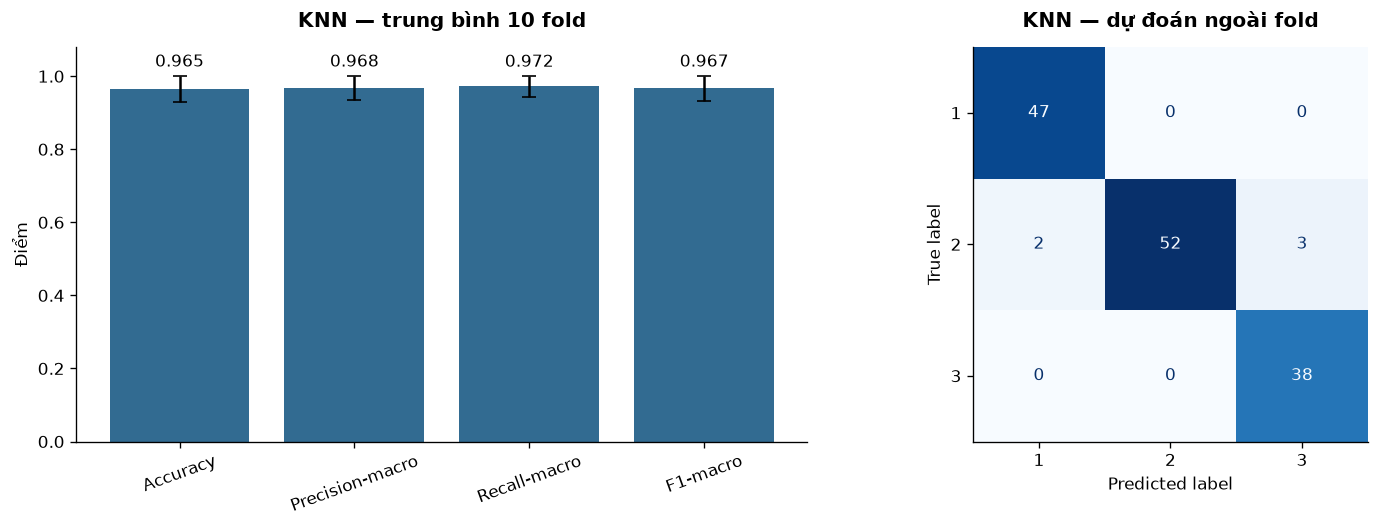

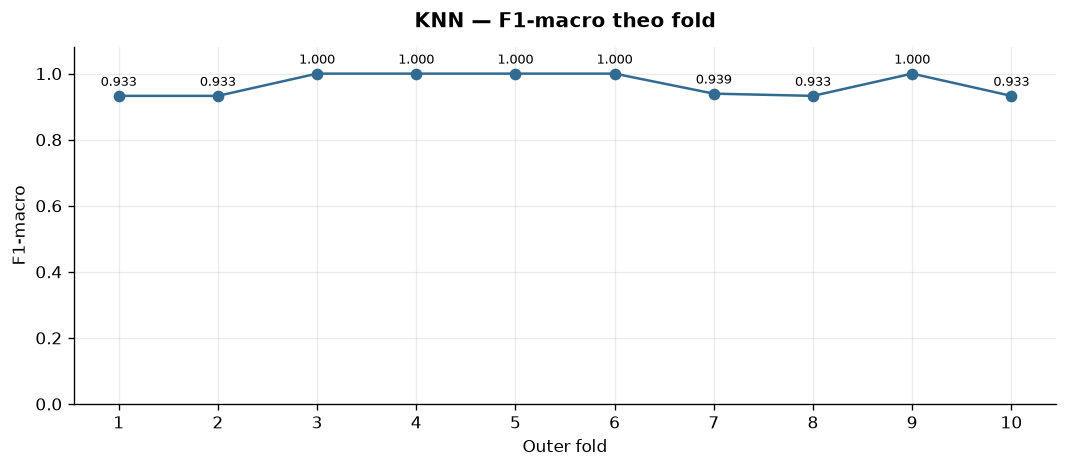

Các cấu hình tốt nhất trên CV 10-fold của toàn bộ train


,params,mean_test_score,std_test_score,rank_test_score
9,"{'model__n_neighbors': 7, 'model__p': 1, 'mode...",0.9798,0.0309,1
8,"{'model__n_neighbors': 7, 'model__p': 1, 'mode...",0.9798,0.0309,1
20,"{'model__n_neighbors': 15, 'model__p': 1, 'mod...",0.9737,0.0322,3
21,"{'model__n_neighbors': 15, 'model__p': 1, 'mod...",0.9737,0.0322,3
17,"{'model__n_neighbors': 11, 'model__p': 1, 'mod...",0.9731,0.0330,5
16,"{'model__n_neighbors': 11, 'model__p': 1, 'mod...",0.9731,0.0330,5
12,"{'model__n_neighbors': 9, 'model__p': 1, 'mode...",0.9731,0.0330,5
13,"{'model__n_neighbors': 9, 'model__p': 1, 'mode...",0.9731,0.0330,5
23,"{'model__n_neighbors': 15, 'model__p': 2, 'mod...",0.9671,0.0444,9
22,"{'model__n_neighbors': 15, 'model__p': 2, 'mod...",0.9671,0.0444,9


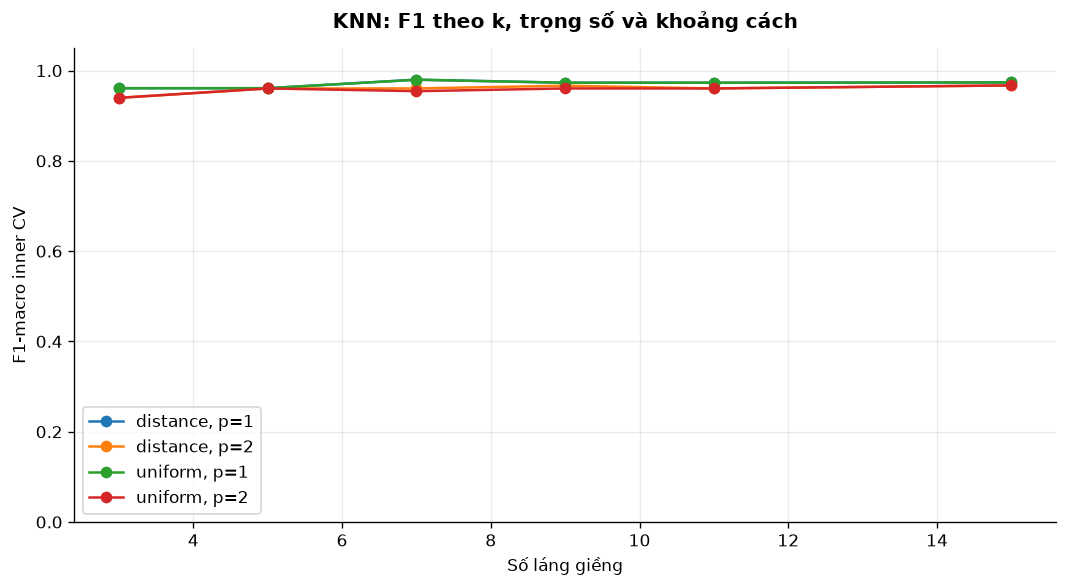


PHÂN TÍCH SỐ LIỆU: KNN
Hiệu năng outer CV: Accuracy=0.965, Precision-macro=0.968, Recall-macro=0.972, F1-macro=0.967 (SD=0.035).
F1 dao động từ 0.933 đến 1.000 qua 10 fold.
Diễn giải: điểm giữa các fold tương đối ổn định trong phép chia này.


,Precision,Recall,F1-score,Số mẫu
Lớp,,,,
1,0.959,1.000,0.979,47.0
2,1.000,0.912,0.954,57.0
3,0.927,1.000,0.962,38.0


Lớp 2 có F1 thấp nhất (0.954), lớp 1 cao nhất (0.979).
Ma trận nhầm lẫn: nhầm nhiều nhất 3 mẫu lớp 2 thành lớp 3.
Tham số cuối được chọn: {'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'uniform'}. F1 inner CV của cấu hình này=0.980; cấu hình kế tiếp=0.980.
Hai cấu hình tốt nhất có điểm gần nhau, nên khác biệt nhỏ giữa chúng không nên được diễn giải quá mức.
Outer folds chọn 6 cấu hình khác nhau; cấu hình thường gặp nhất xuất hiện 3/10 lần.
Ý nghĩa: cấu hình cuối được fit trên toàn train; điểm hiệu năng nên trích dẫn từ outer CV, không lấy điểm inner CV này.


In [26]:
# Đánh giá KNN
knn_scores, knn_pred, knn_search = evaluate_model("KNN", knn, knn_grid)
knn_report = report_model("KNN", knn_scores, knn_pred, knn_search)
knn_cv = pd.DataFrame(knn_search.cv_results_)
fig, ax = plt.subplots(figsize=(9, 5))
for (weight, pvalue), group in knn_cv.groupby(["param_model__weights", "param_model__p"]):
    ax.plot(group["param_model__n_neighbors"].astype(int), group["mean_test_score"],
            marker="o", label=f"{weight}, p={pvalue}")
ax.set(xlabel="Số láng giềng", ylabel="F1-macro inner CV", ylim=(0,1.05),
       title="KNN: F1 theo k, trọng số và khoảng cách")
ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
interpret_model("KNN", knn_scores, knn_pred, knn_report, knn_search)

## Gaussian Naive Bayes

GaussianNB ước lượng phân phối Gaussian theo lớp cho từng thuộc tính rồi kết hợp xác suất, dựa trên giả định độc lập có điều kiện. Các phép đo hóa học có thể tương quan, nên cần xem chỉ số theo lớp và nhầm lẫn, không chỉ F1 tổng.

`var_smoothing` thêm một lượng nhỏ vào phương sai để tránh ước lượng quá sát về 0. Thử 13 giá trị cách đều trên thang log từ `1e-12` đến `1`, vì tác động của tham số trải qua nhiều bậc độ lớn. Đầu thấp biểu diễn làm trơn rất nhẹ, đầu cao là làm trơn mạnh. Nếu cấu hình thắng nằm ở biên, dải cần khảo sát thêm trong thí nghiệm mới. Scaler trong Pipeline làm thống nhất thang đo và được fit riêng trong mỗi fold.

In [27]:
# Khởi tạo Gaussian Naive Bayes và lưới tham số
naive_bayes = Pipeline([
    ("scale", StandardScaler()),
    ("model", GaussianNB()),
])
naive_bayes_grid = {"model__var_smoothing": np.logspace(-12, 0, 13).tolist()}

### Tìm tham số và đánh giá Gaussian Naive Bayes

Gaussian Naive Bayes — fold 01/10 — F1-macro: 0.9327


Gaussian Naive Bayes — fold 02/10 — F1-macro: 0.9327


Gaussian Naive Bayes — fold 03/10 — F1-macro: 1.0000


Gaussian Naive Bayes — fold 04/10 — F1-macro: 0.9327


Gaussian Naive Bayes — fold 05/10 — F1-macro: 1.0000


Gaussian Naive Bayes — fold 06/10 — F1-macro: 1.0000


... (6 outputs left out)

Chỉ số theo từng fold


,Mô hình,Fold,Accuracy,Precision-macro,Recall-macro,F1-macro,Tham số vòng trong
0,Gaussian Naive Bayes,1,0.9333,0.9333,0.9444,0.9327,"{""model__var_smoothing"": 1e-12}"
1,Gaussian Naive Bayes,2,0.9333,0.9333,0.9444,0.9327,"{""model__var_smoothing"": 1e-12}"
2,Gaussian Naive Bayes,3,1.0000,1.0000,1.0000,1.0000,"{""model__var_smoothing"": 1e-12}"
3,Gaussian Naive Bayes,4,0.9286,0.9444,0.9333,0.9327,"{""model__var_smoothing"": 0.1}"
4,Gaussian Naive Bayes,5,1.0000,1.0000,1.0000,1.0000,"{""model__var_smoothing"": 1e-12}"
5,Gaussian Naive Bayes,6,1.0000,1.0000,1.0000,1.0000,"{""model__var_smoothing"": 1e-12}"
6,Gaussian Naive Bayes,7,1.0000,1.0000,1.0000,1.0000,"{""model__var_smoothing"": 1.0}"
7,Gaussian Naive Bayes,8,0.8571,0.8889,0.8889,0.8667,"{""model__var_smoothing"": 1.0}"
8,Gaussian Naive Bayes,9,1.0000,1.0000,1.0000,1.0000,"{""model__var_smoothing"": 1e-12}"
9,Gaussian Naive Bayes,10,0.9286,0.9333,0.9444,0.9327,"{""model__var_smoothing"": 0.1}"


Báo cáo phân lớp từ dự đoán ngoài fold


,precision,recall,f1-score,support
1,0.9787,0.9787,0.9787,47.0000
2,0.9811,0.9123,0.9455,57.0000
3,0.9048,1.0000,0.9500,38.0000
accuracy,0.9577,0.9577,0.9577,0.9577
macro avg,0.9549,0.9637,0.9581,142.0000
weighted avg,0.9599,0.9577,0.9577,142.0000


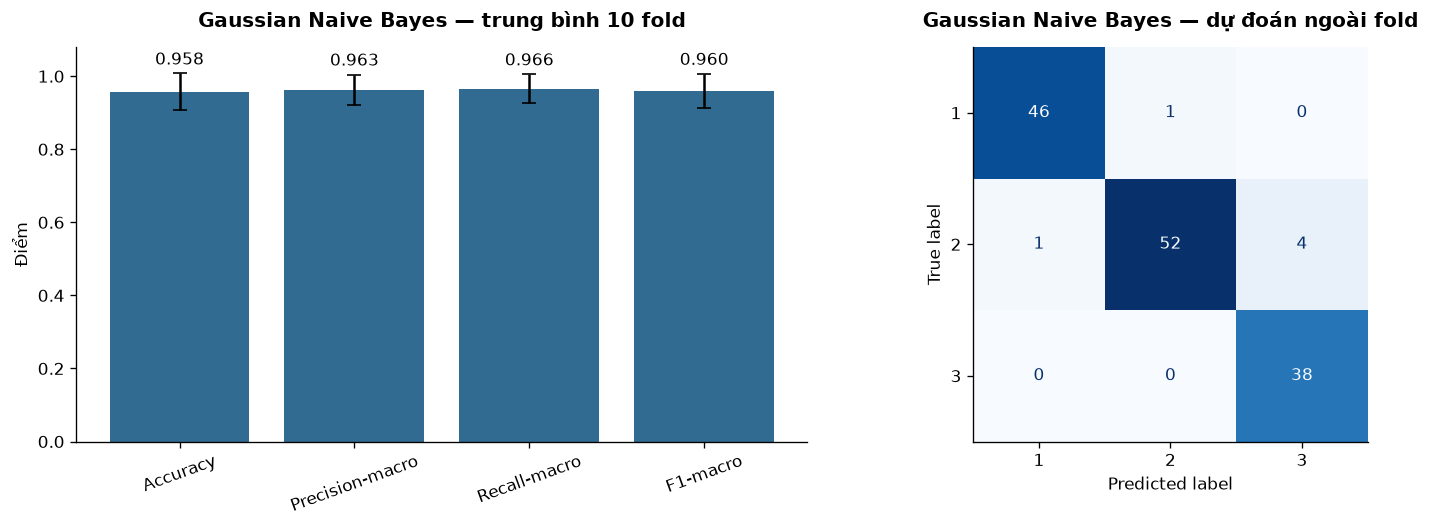

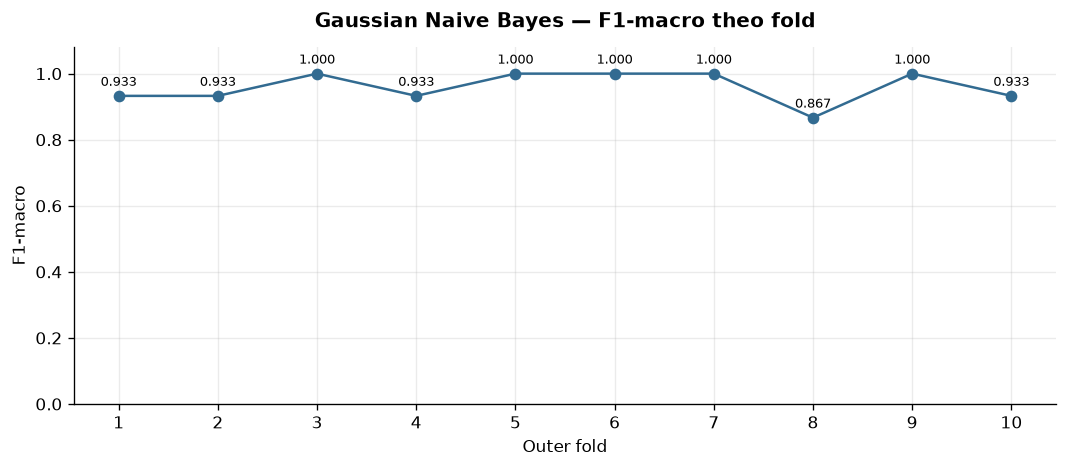

Các cấu hình tốt nhất trên CV 10-fold của toàn bộ train


,params,mean_test_score,std_test_score,rank_test_score
0,{'model__var_smoothing': 1e-12},0.9663,0.0337,1
1,{'model__var_smoothing': 1e-11},0.9663,0.0337,1
2,{'model__var_smoothing': 1e-10},0.9663,0.0337,1
3,{'model__var_smoothing': 1e-09},0.9663,0.0337,1
4,{'model__var_smoothing': 1e-08},0.9663,0.0337,1
5,{'model__var_smoothing': 1e-07},0.9663,0.0337,1
6,{'model__var_smoothing': 1e-06},0.9663,0.0337,1
7,{'model__var_smoothing': 1e-05},0.9663,0.0337,1
8,{'model__var_smoothing': 0.0001},0.9663,0.0337,1
9,{'model__var_smoothing': 0.001},0.9663,0.0337,1


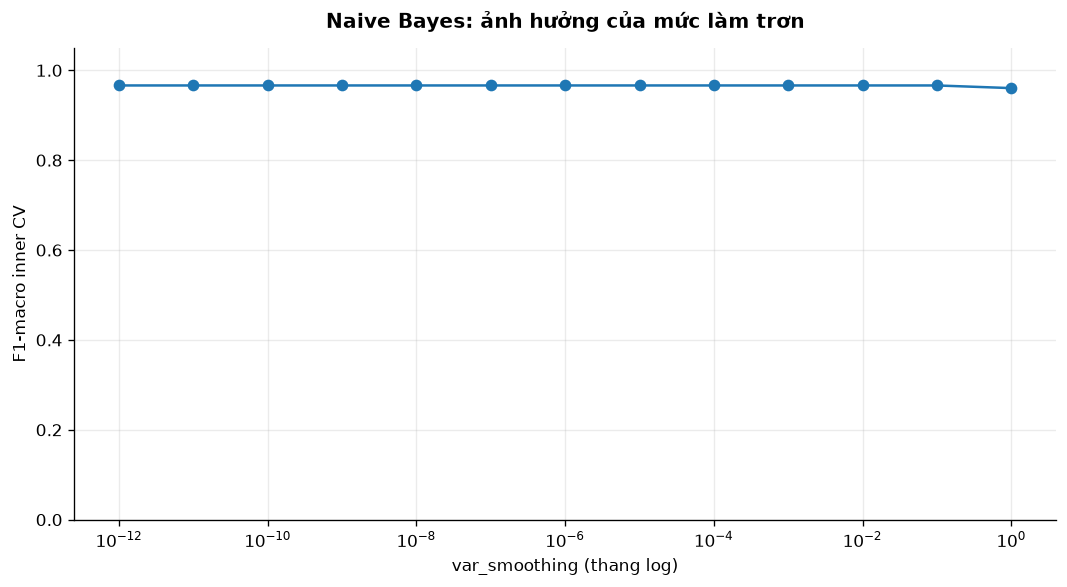


PHÂN TÍCH SỐ LIỆU: Gaussian Naive Bayes
Hiệu năng outer CV: Accuracy=0.958, Precision-macro=0.963, Recall-macro=0.966, F1-macro=0.960 (SD=0.047).
F1 dao động từ 0.867 đến 1.000 qua 10 fold.
Diễn giải: điểm giữa các fold tương đối ổn định trong phép chia này.


,Precision,Recall,F1-score,Số mẫu
Lớp,,,,
1,0.979,0.979,0.979,47.0
2,0.981,0.912,0.945,57.0
3,0.905,1.000,0.950,38.0


Lớp 2 có F1 thấp nhất (0.945), lớp 1 cao nhất (0.979).
Ma trận nhầm lẫn: nhầm nhiều nhất 4 mẫu lớp 2 thành lớp 3.
Tham số cuối được chọn: {'model__var_smoothing': 1e-12}. F1 inner CV của cấu hình này=0.966; cấu hình kế tiếp=0.966.
Hai cấu hình tốt nhất có điểm gần nhau, nên khác biệt nhỏ giữa chúng không nên được diễn giải quá mức.
Outer folds chọn 3 cấu hình khác nhau; cấu hình thường gặp nhất xuất hiện 6/10 lần.
Ý nghĩa: cấu hình cuối được fit trên toàn train; điểm hiệu năng nên trích dẫn từ outer CV, không lấy điểm inner CV này.


In [28]:
nb_scores, nb_pred, nb_search = evaluate_model("Gaussian Naive Bayes", naive_bayes, naive_bayes_grid)
nb_report = report_model("Gaussian Naive Bayes", nb_scores, nb_pred, nb_search)
nb_cv=pd.DataFrame(nb_search.cv_results_).sort_values("param_model__var_smoothing")
fig,ax=plt.subplots(figsize=(9,5))
ax.plot(nb_cv["param_model__var_smoothing"].astype(float),nb_cv["mean_test_score"],marker="o")
ax.set_xscale("log"); ax.set(xlabel="var_smoothing (thang log)",ylabel="F1-macro inner CV",ylim=(0,1.05),title="Naive Bayes: ảnh hưởng của mức làm trơn")
ax.grid(alpha=.25); plt.tight_layout(); plt.show()
interpret_model("Gaussian Naive Bayes", nb_scores, nb_pred, nb_report, nb_search)

## Random Forest

Random Forest gộp nhiều cây, mỗi cây học từ mẫu bootstrap và xét tập con đặc trưng ở mỗi nút. Cây dùng ngưỡng trên từng cột nên không cần chuẩn hóa.

`n_estimators` thử 100 và 200 cây để cân bằng ổn định với thời gian. `max_depth` thử 5, 10 và `None`: cây nông, độ sâu trung bình và không giới hạn. `min_samples_leaf` thử 1 và 2: lá nhỏ nắm ranh giới chi tiết, lá lớn giảm tách theo ít mẫu. `max_features='sqrt'` chọn căn bậc hai của 13 đặc trưng, tức 3 ứng viên mỗi nút. `log2` cũng làm tròn thành 3 với 13 cột, nên cho cấu hình tương đương và được loại khỏi lưới. Lưới còn 12 cấu hình.

In [29]:
# Khởi tạo Random Forest và lưới tham số
random_forest = RandomForestClassifier(random_state=SEED, max_features="sqrt", n_jobs=1)
random_forest_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 2],
}

### Tìm tham số và đánh giá Random Forest

Random Forest — fold 01/10 — F1-macro: 0.9327


Random Forest — fold 02/10 — F1-macro: 0.9327


Random Forest — fold 03/10 — F1-macro: 1.0000


Random Forest — fold 04/10 — F1-macro: 1.0000


Random Forest — fold 05/10 — F1-macro: 1.0000


Random Forest — fold 06/10 — F1-macro: 1.0000


... (6 outputs left out)

Chỉ số theo từng fold


,Mô hình,Fold,Accuracy,Precision-macro,Recall-macro,F1-macro,Tham số vòng trong
0,Random Forest,1,0.9333,0.9333,0.9444,0.9327,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."
1,Random Forest,2,0.9333,0.9333,0.9444,0.9327,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."
2,Random Forest,3,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."
3,Random Forest,4,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 2, ""n_est..."
4,Random Forest,5,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."
5,Random Forest,6,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 2, ""n_est..."
6,Random Forest,7,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."
7,Random Forest,8,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."
8,Random Forest,9,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 2, ""n_est..."
9,Random Forest,10,0.9286,0.9333,0.9444,0.9327,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."


Báo cáo phân lớp từ dự đoán ngoài fold


,precision,recall,f1-score,support
1,0.9792,1.0000,0.9895,47.0000
2,1.0000,0.9474,0.9730,57.0000
3,0.9500,1.0000,0.9744,38.0000
accuracy,0.9789,0.9789,0.9789,0.9789
macro avg,0.9764,0.9825,0.9789,142.0000
weighted avg,0.9797,0.9789,0.9788,142.0000


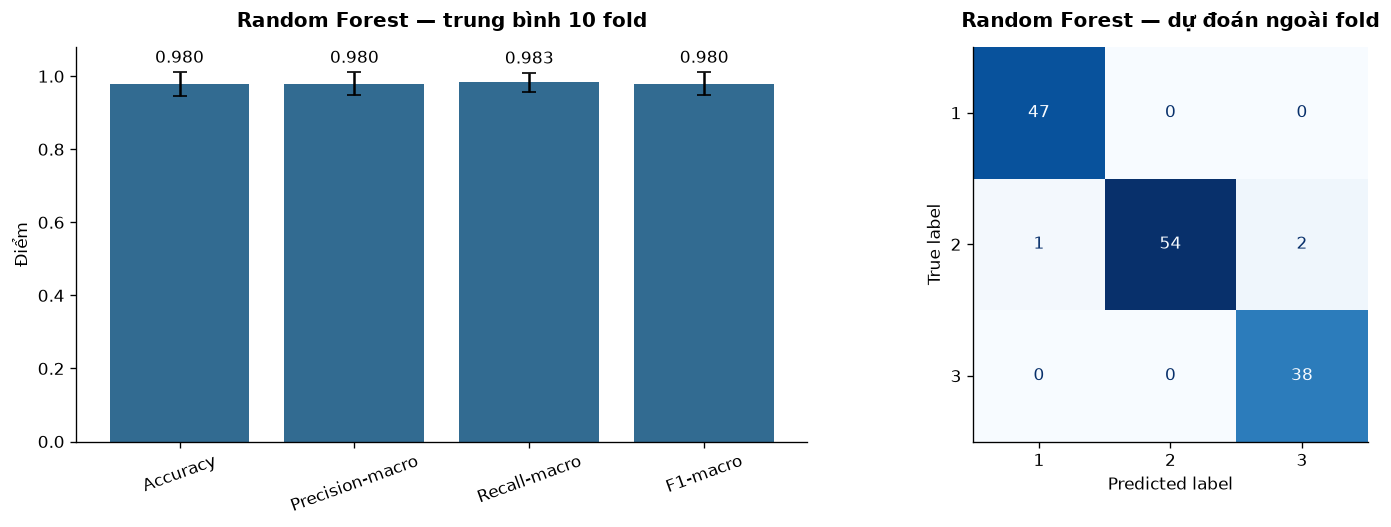

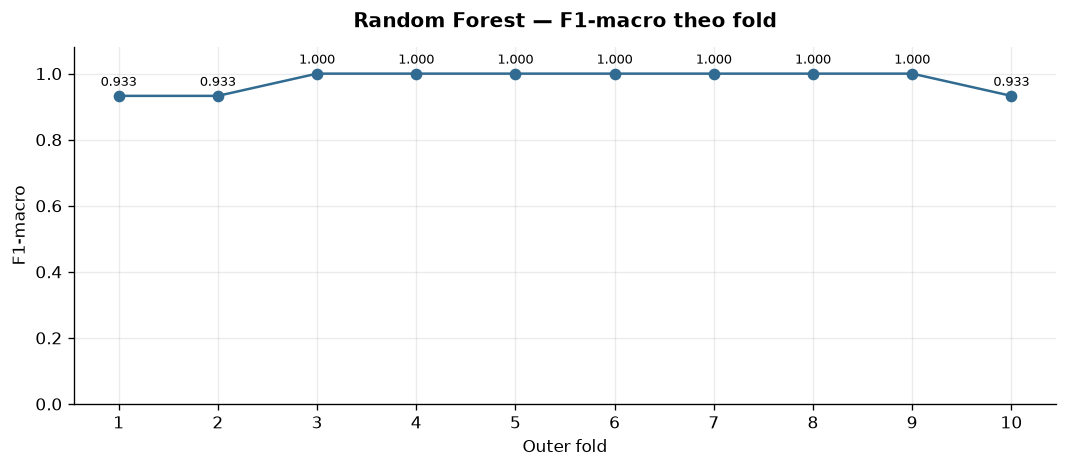

Các cấu hình tốt nhất trên CV 10-fold của toàn bộ train


,params,mean_test_score,std_test_score,rank_test_score
0,"{'max_depth': 5, 'min_samples_leaf': 1, 'n_est...",0.9798,0.0309,1
1,"{'max_depth': 5, 'min_samples_leaf': 1, 'n_est...",0.9798,0.0309,1
2,"{'max_depth': 5, 'min_samples_leaf': 2, 'n_est...",0.9798,0.0309,1
3,"{'max_depth': 5, 'min_samples_leaf': 2, 'n_est...",0.9798,0.0309,1
4,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_es...",0.9798,0.0309,1
5,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_es...",0.9798,0.0309,1
6,"{'max_depth': 10, 'min_samples_leaf': 2, 'n_es...",0.9798,0.0309,1
7,"{'max_depth': 10, 'min_samples_leaf': 2, 'n_es...",0.9798,0.0309,1
8,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.9798,0.0309,1
9,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.9798,0.0309,1


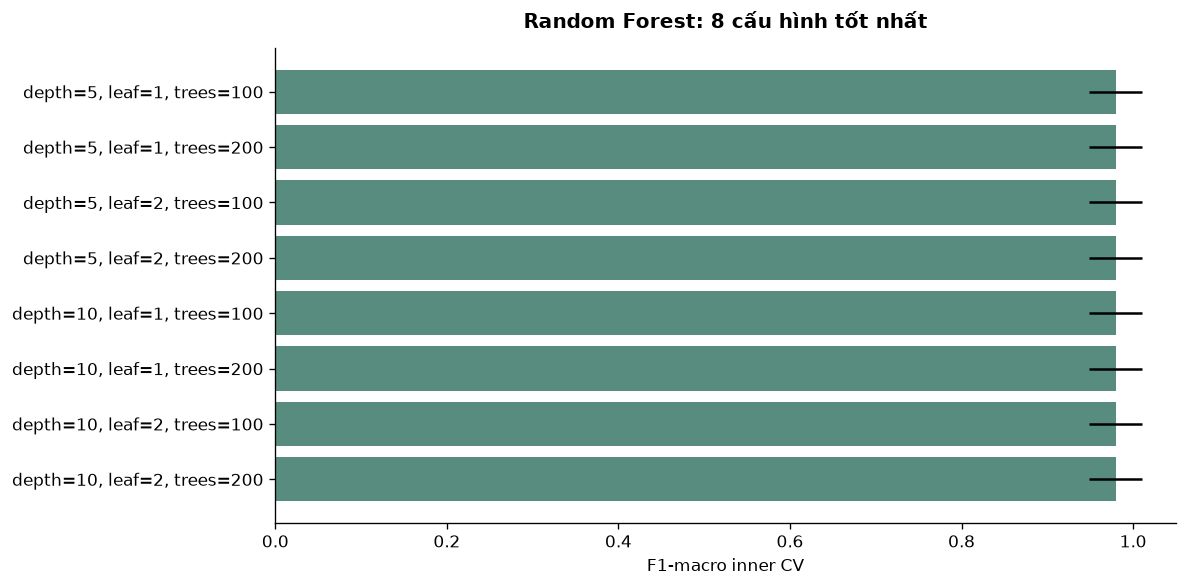


PHÂN TÍCH SỐ LIỆU: Random Forest
Hiệu năng outer CV: Accuracy=0.980, Precision-macro=0.980, Recall-macro=0.983, F1-macro=0.980 (SD=0.033).
F1 dao động từ 0.933 đến 1.000 qua 10 fold.
Diễn giải: điểm giữa các fold tương đối ổn định trong phép chia này.


,Precision,Recall,F1-score,Số mẫu
Lớp,,,,
1,0.979,1.000,0.989,47.0
2,1.000,0.947,0.973,57.0
3,0.950,1.000,0.974,38.0


Lớp 2 có F1 thấp nhất (0.973), lớp 1 cao nhất (0.989).
Ma trận nhầm lẫn: nhầm nhiều nhất 2 mẫu lớp 2 thành lớp 3.
Tham số cuối được chọn: {'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 100}. F1 inner CV của cấu hình này=0.980; cấu hình kế tiếp=0.980.
Hai cấu hình tốt nhất có điểm gần nhau, nên khác biệt nhỏ giữa chúng không nên được diễn giải quá mức.
Outer folds chọn 3 cấu hình khác nhau; cấu hình thường gặp nhất xuất hiện 5/10 lần.
Ý nghĩa: cấu hình cuối được fit trên toàn train; điểm hiệu năng nên trích dẫn từ outer CV, không lấy điểm inner CV này.


In [30]:
rf_scores, rf_pred, rf_search = evaluate_model("Random Forest", random_forest, random_forest_grid)
rf_report = report_model("Random Forest", rf_scores, rf_pred, rf_search)
rf_cv=pd.DataFrame(rf_search.cv_results_).sort_values("rank_test_score")
fig,ax=plt.subplots(figsize=(10,5)); top=rf_cv.head(8)
labels=[f"depth={d}, leaf={l}, trees={t}" for d,l,t in zip(top["param_max_depth"],top["param_min_samples_leaf"],top["param_n_estimators"])]
ax.barh(labels[::-1],top["mean_test_score"].to_numpy()[::-1],xerr=top["std_test_score"].to_numpy()[::-1],color="#588c7e")
ax.set(xlim=(0,1.05),xlabel="F1-macro inner CV",title="Random Forest: 8 cấu hình tốt nhất")
plt.tight_layout(); plt.show()
interpret_model("Random Forest", rf_scores, rf_pred, rf_report, rf_search)

## So sánh mô hình và kết luận

So sánh chính dựa trên F1-macro trung bình của mười dự đoán ngoài fold. Tham số tối ưu của mỗi mô hình được tìm trong CV riêng; outer fold dùng để đánh giá sau lựa chọn tham số. Vì mọi mô hình dùng cùng outer folds, các điểm được so trên cùng những nhóm mẫu.

Đọc kết quả theo thứ tự. Trước tiên xếp hạng F1-macro, rồi xem khoảng cách giữa các mô hình và độ lệch chuẩn theo fold. Sau đó kiểm tra Precision và Recall của từng lớp, ma trận nhầm lẫn và sự ổn định trên đồ thị fold. Accuracy cao có thể che khuất một lớp dự đoán kém, còn F1-macro làm rõ hơn sự cân bằng giữa precision và recall của các lớp.

In [31]:
# Bảng so sánh theo định dạng yêu cầu
results = pd.concat([knn_scores, nb_scores, rf_scores], ignore_index=True)
metrics = ["Accuracy", "Precision-macro", "Recall-macro", "F1-macro"]
means = results.groupby("Mô hình")[metrics].mean().sort_values("F1-macro", ascending=False)
stds = results.groupby("Mô hình")[metrics].std(ddof=1).reindex(means.index)
best_params = {
    "KNN": knn_search.best_params_,
    "Gaussian Naive Bayes": nb_search.best_params_,
    "Random Forest": rf_search.best_params_,
}
comparison = pd.DataFrame({
    "Mô hình": means.index,
    "Tham số tốt nhất": [
        json.dumps({key.removeprefix("model__"): value for key, value in best_params[name].items()},
                   sort_keys=True)
        for name in means.index
    ],
    "F-Score (k=10)": means["F1-macro"].to_numpy(),
    "Độ lệch chuẩn F1": stds["F1-macro"].to_numpy(),
})
display(comparison.round(4))
print("F-Score lấy từ outer CV. Tham số lấy từ GridSearchCV trên toàn bộ train.")
print("Thứ hạng theo F1-macro trung bình:")
for rank, (name, row) in enumerate(means.iterrows(), start=1):
    print(f"{rank}. {name}: F1={row['F1-macro']:.4f} ± {stds.loc[name, 'F1-macro']:.4f}; "
          f"Accuracy={row['Accuracy']:.4f}; Precision-macro={row['Precision-macro']:.4f}; "
          f"Recall-macro={row['Recall-macro']:.4f}")

# Chênh lệch F1 theo điểm phần trăm so với mô hình xếp đầu
leader = means.index[0]
gap = (means["F1-macro"] - means.loc[leader, "F1-macro"]) * 100
gap_table = pd.DataFrame({"F1-macro": means["F1-macro"], "Chênh với mô hình đầu (điểm %)": gap})
display(gap_table.round(2))
print(f"Mô hình xếp đầu theo tiêu chí đặt trước là {leader}. "
      f"Khoảng cách với mô hình thứ hai là "
      f"{(means.iloc[0]['F1-macro'] - means.iloc[1]['F1-macro'])*100:.2f} điểm phần trăm.")

# Hiệu năng riêng từng lớp từ dự đoán outer-fold
reports = {
    "KNN": knn_report,
    "Gaussian Naive Bayes": nb_report,
    "Random Forest": rf_report,
}
class_rows = []
for model_name, report in reports.items():
    for label in classes:
        entry = report[str(label)]
        class_rows.append({
            "Mô hình": model_name, "Lớp": label,
            "Precision": entry["precision"], "Recall": entry["recall"],
            "F1-score": entry["f1-score"], "Số mẫu": int(entry["support"]),
        })
class_metrics = pd.DataFrame(class_rows)
display(class_metrics.pivot(index="Lớp", columns="Mô hình",
                            values=["Precision", "Recall", "F1-score"]).round(3))

# Lưu bảng phục vụ báo cáo
result_dir = data_dir / "wine_comparison"
result_dir.mkdir(exist_ok=True)
comparison.to_csv(result_dir / "comparison_cv.csv", index=False, encoding="utf-8-sig")
means.join(stds.add_suffix(" (độ lệch chuẩn)")).to_csv(
    result_dir / "metrics_cv.csv", encoding="utf-8-sig")
results.to_csv(result_dir / "fold_metrics.csv", index=False, encoding="utf-8-sig")
class_metrics.to_csv(result_dir / "class_metrics_cv.csv", index=False, encoding="utf-8-sig")
# Ghép điểm F1 theo fold để đối chiếu các mô hình trên đúng cùng phần validation
fold_pivot = results.pivot(index="Fold", columns="Mô hình", values="F1-macro")
if fold_pivot.isna().any().any() or fold_pivot.shape[0] != N_SPLITS:
    raise ValueError("Cần đủ F1 của cả ba mô hình trên cùng 10 outer folds.")

# So sánh cặp trên cùng folds, không xem các fold là các mẫu độc lập để suy luận ý nghĩa thống kê
print("5. Chênh lệch F1 theo cặp trên cùng folds (đơn vị: điểm phần trăm):")
pair_rows = []
model_names = list(means.index)
for i, first in enumerate(model_names):
    for second in model_names[i+1:]:
        delta = (fold_pivot[first] - fold_pivot[second]) * 100
        pair_rows.append({
            "So sánh": f"{first} − {second}",
            "Chênh lệch trung bình": delta.mean(),
            "Fold đầu cao hơn": int((delta > 0).sum()),
            "Hòa": int((delta == 0).sum()),
            "Fold thứ hai cao hơn": int((delta < 0).sum()),
        })
pairwise = pd.DataFrame(pair_rows)
display(pairwise.round(2))

,Mô hình,Tham số tốt nhất,F-Score (k=10),Độ lệch chuẩn F1
0,Random Forest,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est...",0.9798,0.0325
1,KNN,"{""n_neighbors"": 7, ""p"": 1, ""weights"": ""uniform""}",0.9670,0.0348
2,Gaussian Naive Bayes,"{""var_smoothing"": 1e-12}",0.9597,0.0468


F-Score lấy từ outer CV. Tham số lấy từ GridSearchCV trên toàn bộ train.
Thứ hạng theo F1-macro trung bình:
1. Random Forest: F1=0.9798 ± 0.0325; Accuracy=0.9795; Precision-macro=0.9800; Recall-macro=0.9833
2. KNN: F1=0.9670 ± 0.0348; Accuracy=0.9652; Precision-macro=0.9678; Recall-macro=0.9722
3. Gaussian Naive Bayes: F1=0.9597 ± 0.0468; Accuracy=0.9581; Precision-macro=0.9633; Recall-macro=0.9656


,F1-macro,Chênh với mô hình đầu (điểm %)
Mô hình,,
Random Forest,0.98,0.00
KNN,0.97,-1.28
Gaussian Naive Bayes,0.96,-2.01


Mô hình xếp đầu theo tiêu chí đặt trước là Random Forest. Khoảng cách với mô hình thứ hai là 1.28 điểm phần trăm.


Precision                                    Recall         \
Mô hình Gaussian Naive Bayes    KNN Random Forest Gaussian Naive Bayes    KNN   
Lớp                                                                             
1                      0.979  0.959         0.979                0.979  1.000   
2                      0.981  1.000         1.000                0.912  0.912   
3                      0.905  0.927         0.950                1.000  1.000   

                                  F1-score                       
Mô hình Random Forest Gaussian Naive Bayes    KNN Random Forest  
Lớp                                                              
1               1.000                0.979  0.979         0.989  
2               0.947                0.945  0.954         0.973  
3               1.000                0.950  0.962         0.974

5. Chênh lệch F1 theo cặp trên cùng folds (đơn vị: điểm phần trăm):


,So sánh,Chênh lệch trung bình,Fold đầu cao hơn,Hòa,Fold thứ hai cao hơn
0,Random Forest − KNN,1.28,2,8,0
1,Random Forest − Gaussian Naive Bayes,2.01,2,8,0
2,KNN − Gaussian Naive Bayes,0.73,2,7,1


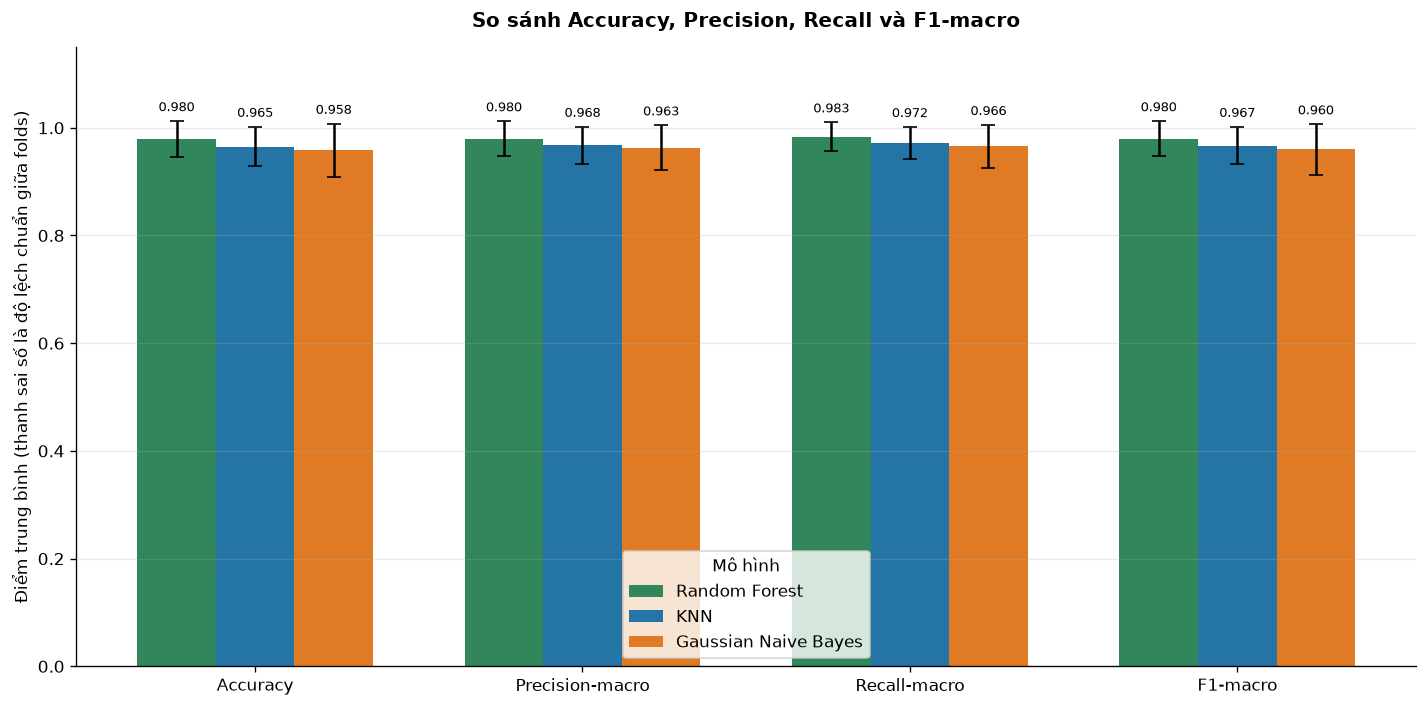

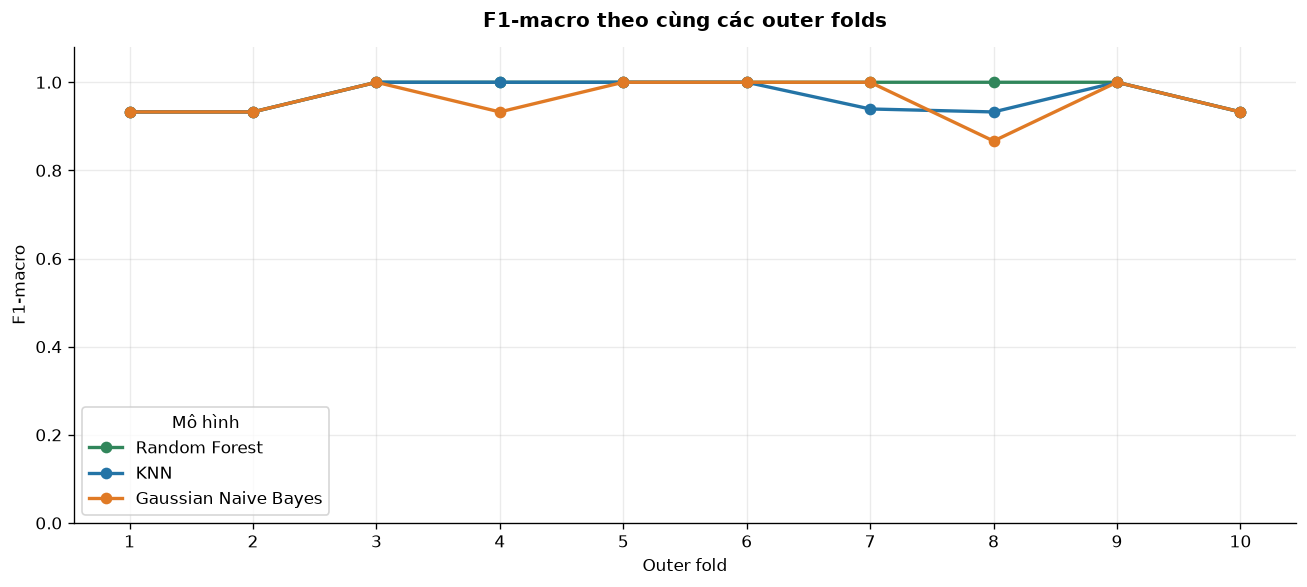

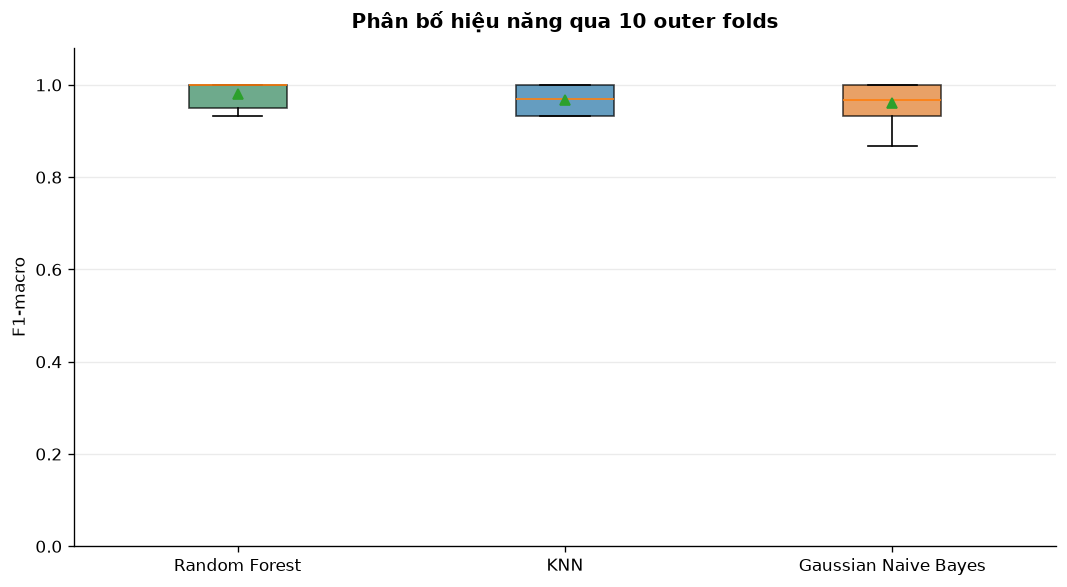

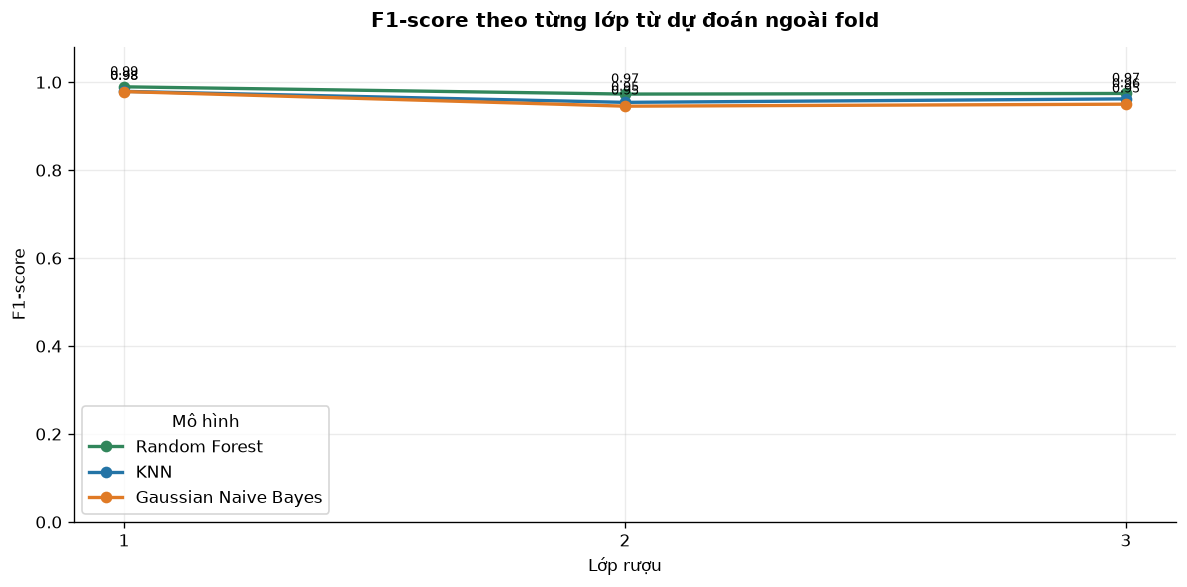

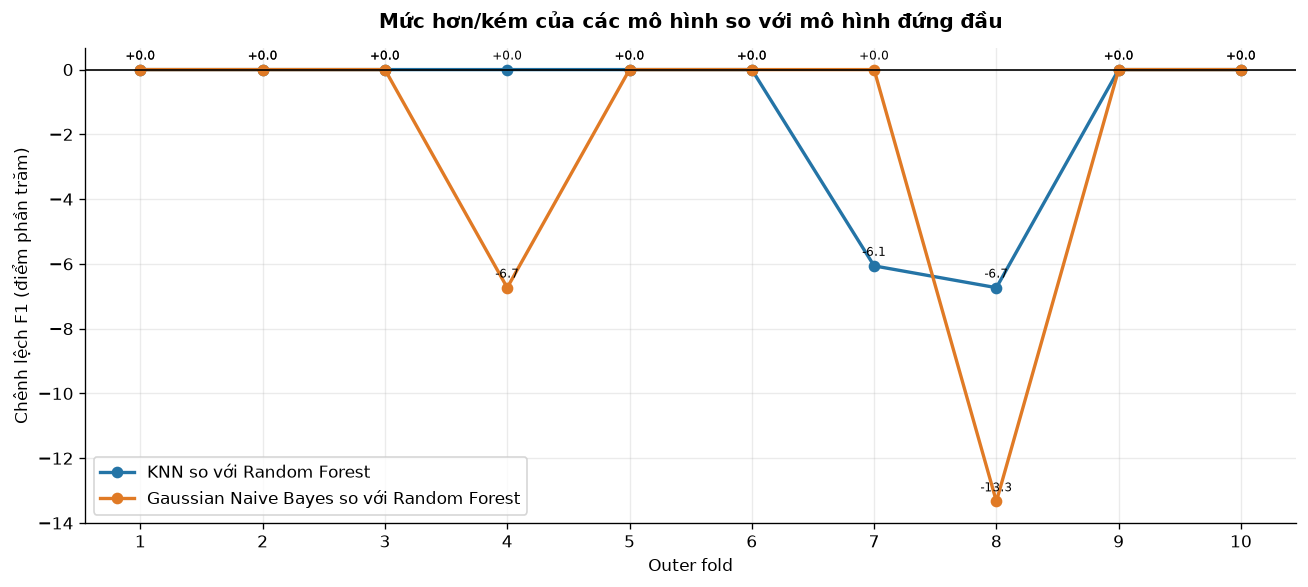

In [32]:
# Biểu đồ tổng hợp chất lượng, độ ổn định và chỉ số theo lớp
model_order = means.index.tolist()
palette = {"KNN": "#2474A6", "Gaussian Naive Bayes": "#E07A25",
           "Random Forest": "#31865B"}

# Bốn metric kèm độ lệch chuẩn giữa outer folds
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(metrics))
width = 0.24
for index, model_name in enumerate(model_order):
    values = means.loc[model_name, metrics].to_numpy()
    errors = stds.loc[model_name, metrics].to_numpy()
    bars = ax.bar(x + (index - 1) * width, values, width,
                  yerr=errors, capsize=4, color=palette[model_name], label=model_name)
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=8)
ax.set_xticks(x, metrics)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Điểm trung bình (thanh sai số là độ lệch chuẩn giữa folds)")
ax.set_title("So sánh Accuracy, Precision, Recall và F1-macro")
ax.legend(title="Mô hình")
ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(result_dir / "overall_metrics.png", dpi=180, bbox_inches="tight")
plt.show()

# So sánh F1 trên cùng từng outer fold
fig, ax = plt.subplots(figsize=(11, 5))
for model_name in model_order:
    subset = results.loc[results["Mô hình"].eq(model_name)]
    ax.plot(subset["Fold"], subset["F1-macro"], marker="o", linewidth=2,
            color=palette[model_name], label=model_name)
ax.set(xticks=range(1, N_SPLITS + 1), ylim=(0, 1.08), xlabel="Outer fold",
       ylabel="F1-macro", title="F1-macro theo cùng các outer folds")
ax.grid(alpha=.25)
ax.legend(title="Mô hình")
fig.tight_layout()
fig.savefig(result_dir / "f1_by_fold.png", dpi=180, bbox_inches="tight")
plt.show()

# Phân bố mười điểm F1, trung vị, các tứ phân vị và trung bình
fig, ax = plt.subplots(figsize=(9, 5))
box = ax.boxplot([results.loc[results["Mô hình"].eq(name), "F1-macro"]
                  for name in model_order], tick_labels=model_order,
                 showmeans=True, patch_artist=True)
for patch, name in zip(box["boxes"], model_order):
    patch.set_facecolor(palette[name])
    patch.set_alpha(.7)
ax.set(ylim=(0, 1.08), ylabel="F1-macro",
       title="Phân bố hiệu năng qua 10 outer folds")
ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(result_dir / "f1_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

# F1 của từng lớp để làm rõ lớp khó phân loại
fig, ax = plt.subplots(figsize=(10, 5))
for model_name in model_order:
    subset = class_metrics.loc[class_metrics["Mô hình"].eq(model_name)]
    ax.plot(subset["Lớp"], subset["F1-score"], marker="o", linewidth=2,
            color=palette[model_name], label=model_name)
    for _, row in subset.iterrows():
        ax.annotate(f"{row['F1-score']:.2f}", (row["Lớp"], row["F1-score"]),
                    textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set(xticks=classes, ylim=(0, 1.08), xlabel="Lớp rượu", ylabel="F1-score",
       title="F1-score theo từng lớp từ dự đoán ngoài fold")
ax.grid(alpha=.25)
ax.legend(title="Mô hình")
fig.tight_layout()
fig.savefig(result_dir / "class_f1.png", dpi=180, bbox_inches="tight")
plt.show()

# Chênh lệch F1-macro theo từng fold so với mô hình xếp đầu
fig, ax = plt.subplots(figsize=(11, 5))
for name in model_order[1:]:
    delta = (fold_pivot[name] - fold_pivot[leader]) * 100
    ax.plot(delta.index, delta.values, marker="o", linewidth=2,
            color=palette[name], label=f"{name} so với {leader}")
    for fold, value in delta.items():
        ax.annotate(f"{value:+.1f}", (fold, value), textcoords="offset points",
                    xytext=(0, 6), ha="center", fontsize=7)
ax.axhline(0, color="black", linewidth=1)
ax.set(xticks=range(1, N_SPLITS + 1), xlabel="Outer fold",
       ylabel="Chênh lệch F1 (điểm phần trăm)",
       title="Mức hơn/kém của các mô hình so với mô hình đứng đầu")
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(result_dir / "paired_f1_difference.png", dpi=180, bbox_inches="tight")
plt.show()

## Kết luận dựa trên kết quả chạy

Ngay sau bảng, notebook in nhận định định lượng từ số liệu vừa tính: thứ hạng theo F1-macro, mức cách biệt với mô hình kế tiếp, trung bình ± độ lệch chuẩn và khoảng điểm min–max của từng mô hình. Phần phân tích theo lớp nêu F1 và Recall cao nhất/thấp nhất, số mẫu hỗ trợ và cặp nhầm lẫn xuất hiện nhiều nhất. Bảng so sánh cặp đếm số outer folds mô hình nào đạt F1 cao hơn.

Đọc các hình cùng phần nhận định. Biểu đồ chỉ số tổng thể so sánh bốn thước đo. Đường F1 theo fold và boxplot thể hiện dao động. Đồ thị chênh lệch theo fold cho biết mô hình nào thắng ở từng lần chia. Đồ thị F1 theo lớp và ma trận nhầm lẫn chỉ ra nguồn gốc chênh lệch hiệu năng.

Kết luận cần ghi mô hình đứng đầu theo tiêu chí F1-macro và nêu số liệu cụ thể. Nếu chênh lệch trung bình nhỏ nhưng độ lệch chuẩn lớn, mô tả kết quả là gần nhau hoặc chưa ổn định. CV chỉ đánh giá trên train. Muốn báo cáo hiệu năng cuối cùng trên test, cần chốt lựa chọn trước rồi đánh giá test một lần.

In [33]:
# Nhận định định lượng — tính trực tiếp từ kết quả chạy, không hard-code số liệu
def describe_params(name, params):
    p = {key.removeprefix("model__"): value for key, value in params.items()}
    if name == "KNN":
        distance = "Manhattan" if p["p"] == 1 else "Euclidean"
        return f"k={p['n_neighbors']}, {distance} (p={p['p']}), weights={p['weights']}"
    if name == "Gaussian Naive Bayes":
        return f"var_smoothing={p['var_smoothing']:g}"
    depth = "không giới hạn" if p["max_depth"] is None else p["max_depth"]
    return f"{p['n_estimators']} cây, độ sâu {depth}, leaf={p['min_samples_leaf']}, max_features=sqrt"

searches = {"KNN": knn_search, "Gaussian Naive Bayes": nb_search, "Random Forest": rf_search}
oof_predictions = {"KNN": knn_pred, "Gaussian Naive Bayes": nb_pred, "Random Forest": rf_pred}

rank_rows = []
for rank, name in enumerate(means.index, start=1):
    fold_f1 = results.loc[results["Mô hình"].eq(name), "F1-macro"]
    rank_rows.append({
        "Hạng theo F1": rank, "Mô hình": name,
        "Tham số cuối chọn trên toàn train": describe_params(name, searches[name].best_params_),
        "F1-macro outer CV": means.loc[name, "F1-macro"],
        "SD giữa folds": stds.loc[name, "F1-macro"],
        "Min–max": f"{fold_f1.min():.4f}–{fold_f1.max():.4f}",
    })
display(pd.DataFrame(rank_rows).round(4))

leader_name = means.index[0]
gap_second = (means.iloc[0]["F1-macro"] - means.iloc[1]["F1-macro"]) * 100
gap_third = (means.iloc[0]["F1-macro"] - means.iloc[2]["F1-macro"]) * 100
stability = ("Khoảng cách giữa mô hình đầu và mô hình thứ hai nhỏ hơn độ lệch chuẩn giữa folds, "
             "nên chưa cho thấy khác biệt lớn, ổn định rõ rệt."
             if gap_second / 100 < stds["F1-macro"].max() else
             "Khoảng cách giữa mô hình đầu và mô hình thứ hai lớn hơn độ lệch chuẩn giữa folds.")

paragraphs = []
for name in means.index:
    fold_f1 = results.loc[results["Mô hình"].eq(name), "F1-macro"]
    predicted = oof_predictions[name]
    acc = accuracy_score(y, predicted)
    correct = int((predicted == y.to_numpy()).sum())
    class_table = pd.DataFrame(reports[name]).T.loc[[str(k) for k in classes]]
    weak = int(class_table["f1-score"].astype(float).idxmin())
    weak_recall = float(class_table.loc[str(weak), "recall"])
    weak_f1 = float(class_table.loc[str(weak), "f1-score"])
    matrix = confusion_matrix(y, predicted, labels=classes)
    errors = [(matrix[i, j], classes[i], classes[j])
              for i in range(len(classes)) for j in range(len(classes)) if i != j]
    count, actual, wrong = max(errors)
    perfect = int((fold_f1 == 1.0).sum())
    text = (f"**{name}** đạt F1={fold_f1.mean():.4f}±{fold_f1.std(ddof=1):.4f}, "
            f"accuracy ngoài fold {acc:.4f} (đúng {correct}/{len(y)} mẫu OOF). "
            f"{perfect}/10 folds đạt F1=1.000, fold thấp nhất {fold_f1.min():.4f}. "
            f"Lớp {weak} khó nhất: recall {weak_recall:.4f}, F1 {weak_f1:.3f}. "
            f"Nhầm lẫn nhiều nhất: {count} mẫu lớp {actual} thành lớp {wrong}. "
            f"Tham số cuối: {describe_params(name, searches[name].best_params_)}.")
    if name == "Gaussian Naive Bayes":
        grid_values = np.array(naive_bayes_grid["model__var_smoothing"])
        chosen = searches[name].best_params_["model__var_smoothing"]
        if chosen in (grid_values.min(), grid_values.max()):
            text += (" Nghiệm nằm ở biên của lưới khảo sát; điểm CV chỉ là tốt nhất trong 13 mức đã thử,"
                     " muốn xác định optimum hai phía cần đặt lưới mới rộng hơn.")
    paragraphs.append(text)

display(Markdown(
    "Các số liệu dưới đây được tính trực tiếp từ lần chạy nested stratified 10×10 CV của notebook này "
    "trên bộ train 142 mẫu, dùng chung seed và outer folds cho ba thuật toán. "
    "Đây là kết quả cross-validation trên train, chưa phải đánh giá tập test.\n\n"
    "F1-macro outer CV là trung bình mười điểm validation ngoài; SD mô tả độ dao động giữa các lần chia, "
    "không phải khoảng tin cậy. "
    f"Khoảng cách từ {leader_name} tới mô hình thứ hai là **{gap_second:.2f} điểm phần trăm**, "
    f"tới mô hình thứ ba là **{gap_third:.2f} điểm phần trăm**. {stability}\n\n"
    + "\n\n".join(paragraphs)
    + "\n\n**Kết luận so sánh.** Theo tiêu chí định trước là F1-macro outer CV, thứ hạng là "
    + " > ".join(f"{name} ({means.loc[name, 'F1-macro']:.4f})" for name in means.index)
    + ". Tham số cuối được chọn trên toàn train; điểm hiệu năng trích dẫn từ outer CV. "
    "Không sử dụng các kết quả này như điểm test độc lập."
))

,Hạng theo F1,Mô hình,Tham số cuối chọn trên toàn train,F1-macro outer CV,SD giữa folds,Min–max
0,1,Random Forest,"100 cây, độ sâu 5, leaf=1, max_features=sqrt",0.9798,0.0325,0.9327–1.0000
1,2,KNN,"k=7, Manhattan (p=1), weights=uniform",0.9670,0.0348,0.9327–1.0000
2,3,Gaussian Naive Bayes,var_smoothing=1e-12,0.9597,0.0468,0.8667–1.0000


Các số liệu dưới đây được tính trực tiếp từ lần chạy nested stratified 10×10 CV của notebook này trên bộ train 142 mẫu, dùng chung seed và outer folds cho ba thuật toán. Đây là kết quả cross-validation trên train, chưa phải đánh giá tập test.

F1-macro outer CV là trung bình mười điểm validation ngoài; SD mô tả độ dao động giữa các lần chia, không phải khoảng tin cậy. Khoảng cách từ Random Forest tới mô hình thứ hai là **1.28 điểm phần trăm**, tới mô hình thứ ba là **2.01 điểm phần trăm**. Khoảng cách giữa mô hình đầu và mô hình thứ hai nhỏ hơn độ lệch chuẩn giữa folds, nên chưa cho thấy khác biệt lớn, ổn định rõ rệt.

**Random Forest** đạt F1=0.9798±0.0325, accuracy ngoài fold 0.9789 (đúng 139/142 mẫu OOF). 7/10 folds đạt F1=1.000, fold thấp nhất 0.9327. Lớp 2 khó nhất: recall 0.9474, F1 0.973. Nhầm lẫn nhiều nhất: 2 mẫu lớp 2 thành lớp 3. Tham số cuối: 100 cây, độ sâu 5, leaf=1, max_features=sqrt.

**KNN** đạt F1=0.9670±0.0348, accuracy ngoài fold 0.9648 (đúng 137/142 mẫu OOF). 5/10 folds đạt F1=1.000, fold thấp nhất 0.9327. Lớp 2 khó nhất: recall 0.9123, F1 0.954. Nhầm lẫn nhiều nhất: 3 mẫu lớp 2 thành lớp 3. Tham số cuối: k=7, Manhattan (p=1), weights=uniform.

**Gaussian Naive Bayes** đạt F1=0.9597±0.0468, accuracy ngoài fold 0.9577 (đúng 136/142 mẫu OOF). 5/10 folds đạt F1=1.000, fold thấp nhất 0.8667. Lớp 2 khó nhất: recall 0.9123, F1 0.945. Nhầm lẫn nhiều nhất: 4 mẫu lớp 2 thành lớp 3. Tham số cuối: var_smoothing=1e-12. Nghiệm nằm ở biên của lưới khảo sát; điểm CV chỉ là tốt nhất trong 13 mức đã thử, muốn xác định optimum hai phía cần đặt lưới mới rộng hơn.

**Kết luận so sánh.** Theo tiêu chí định trước là F1-macro outer CV, thứ hạng là Random Forest (0.9798) > KNN (0.9670) > Gaussian Naive Bayes (0.9597). Tham số cuối được chọn trên toàn train; điểm hiệu năng trích dẫn từ outer CV. Không sử dụng các kết quả này như điểm test độc lập.

### Chỉ số gộp từ dự đoán ngoài fold (OOF)

Gộp mười dự đoán ngoài fold thành một chuỗi dự đoán duy nhất trên 142 mẫu rồi tính chỉ số một lần. Cách tổng hợp này khác với trung bình chỉ số theo fold ở bảng xếp hạng nên giá trị có thể hơi khác.

,Accuracy,Precision-macro,Recall-macro,F1-macro
Mô hình,,,,
Random Forest,0.9789,0.9764,0.9825,0.9789
KNN,0.9648,0.9620,0.9708,0.9651
Gaussian Naive Bayes,0.9577,0.9549,0.9637,0.9581


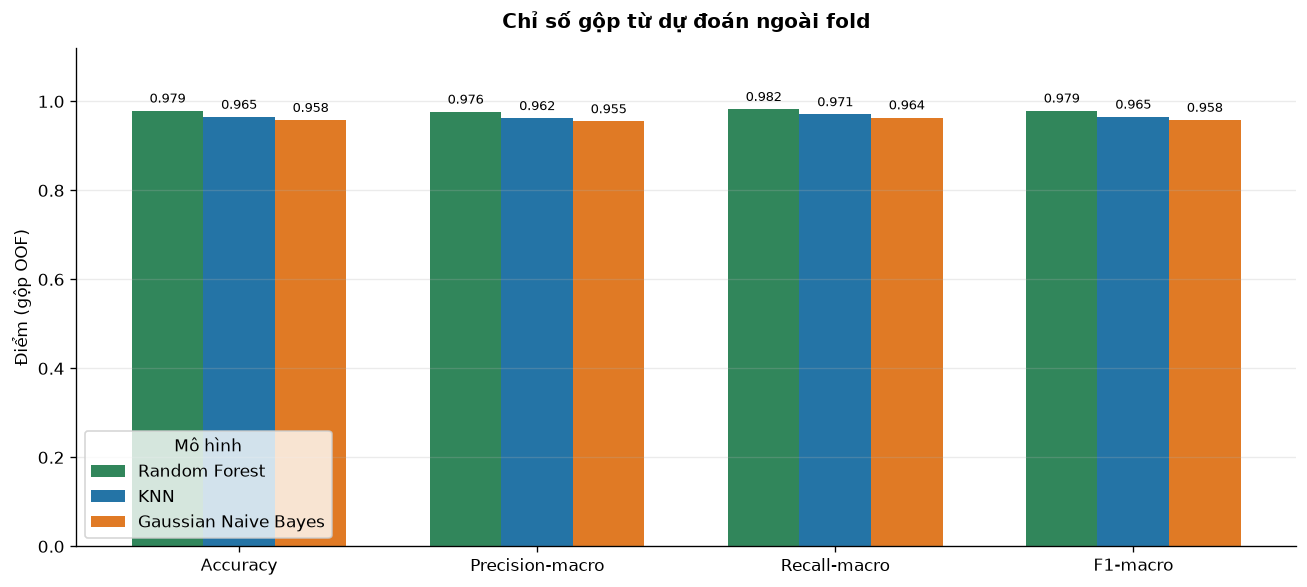

In [34]:
oof_rows = []
for name in means.index:
    predicted = oof_predictions[name]
    oof_rows.append({"Mô hình": name,
                     "Accuracy": accuracy_score(y, predicted),
                     "Precision-macro": precision_score(y, predicted, **macro),
                     "Recall-macro": recall_score(y, predicted, **macro),
                     "F1-macro": f1_score(y, predicted, **macro)})
oof_metrics = pd.DataFrame(oof_rows).set_index("Mô hình")
display(oof_metrics.round(4))
oof_metrics.to_csv(result_dir / "oof_metrics.csv", encoding="utf-8-sig")

palette = {"KNN": "#2474A6", "Gaussian Naive Bayes": "#E07A25", "Random Forest": "#31865B"}
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(oof_metrics.columns))
width = 0.24
for i, name in enumerate(oof_metrics.index):
    bars = ax.bar(x + (i - 1) * width, oof_metrics.loc[name].to_numpy(), width,
                  color=palette[name], label=name)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
ax.set_xticks(x, oof_metrics.columns)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Điểm (gộp OOF)")
ax.set_title("Chỉ số gộp từ dự đoán ngoài fold")
ax.legend(title="Mô hình")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(result_dir / "oof_metrics.png", dpi=180, bbox_inches="tight")
plt.show()

### Bảng chi tiết theo lớp và ma trận nhầm lẫn ngoài fold

Ma trận có hàng là lớp thật và cột là nhãn dự đoán; đường chéo là dự đoán đúng. Classification report gộp OOF và trung bình metric theo fold là hai cách tổng hợp khác nhau nên giá trị F1 của chúng có thể hơi khác. F-Score dùng trong bảng xếp hạng ở trên là trung bình F1-macro của mười outer folds, đúng quy ước đánh giá đã chọn.

In [35]:
display(class_metrics.round(3))
for name in means.index:
    matrix = confusion_matrix(y, oof_predictions[name], labels=classes)
    table = pd.DataFrame(matrix, index=[f"Thật {k}" for k in classes],
                         columns=[f"Dự đoán {k}" for k in classes])
    display(table.rename_axis(name))

,Mô hình,Lớp,Precision,Recall,F1-score,Số mẫu
0,KNN,1,0.959,1.000,0.979,47
1,KNN,2,1.000,0.912,0.954,57
2,KNN,3,0.927,1.000,0.962,38
3,Gaussian Naive Bayes,1,0.979,0.979,0.979,47
4,Gaussian Naive Bayes,2,0.981,0.912,0.945,57
5,Gaussian Naive Bayes,3,0.905,1.000,0.950,38
6,Random Forest,1,0.979,1.000,0.989,47
7,Random Forest,2,1.000,0.947,0.973,57
8,Random Forest,3,0.950,1.000,0.974,38


,Dự đoán 1,Dự đoán 2,Dự đoán 3
Random Forest,,,
Thật 1,47,0,0
Thật 2,1,54,2
Thật 3,0,0,38


,Dự đoán 1,Dự đoán 2,Dự đoán 3
KNN,,,
Thật 1,47,0,0
Thật 2,2,52,3
Thật 3,0,0,38


,Dự đoán 1,Dự đoán 2,Dự đoán 3
Gaussian Naive Bayes,,,
Thật 1,46,1,0
Thật 2,1,52,4
Thật 3,0,0,38


## 4. Gom cụm dữ liệu

Yêu cầu đề bài: **loại trừ cột nhãn** và thực hiện gom cụm với **K-Means** và **DBSCAN**; dùng giá trị nhãn để **đánh giá** kết quả gom cụm (độ đo Adjusted Rand Index — ARI).

**Phạm vi dữ liệu:** gom cụm là học không giám sát nên thực hiện trên **toàn bộ 178 mẫu** — nhãn không tham gia fit, chỉ dùng sau cùng để đánh giá. Việc chia train/test ở phần 3 chỉ phục vụ bài toán phân loại. StandardScaler và PCA của phần này được fit riêng trên toàn bộ dữ liệu (độc lập với scaler/PCA fit trên train ở phần 2).

### 4.1. Chuẩn bị dữ liệu gom cụm

In [36]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

df_full = df_raw.rename(columns=clean_column_name)
X_full = df_full[FEATURES].copy()          # loại trừ cột nhãn
y_full = df_full[TARGET].astype(int)       # nhãn chỉ dùng để đánh giá

scaler_full = StandardScaler()
X_full_scaled = pd.DataFrame(scaler_full.fit_transform(X_full), columns=FEATURES)

pca_vis = PCA(n_components=2, svd_solver="full", random_state=RANDOM_STATE)
coords_full = pca_vis.fit_transform(X_full_scaled)
v1_full, v2_full = pca_vis.explained_variance_ratio_

print("Dữ liệu gom cụm:", X_full_scaled.shape, "— không gồm cột nhãn")
print("Phân bố nhãn (chỉ dùng đánh giá):", y_full.value_counts().sort_index().to_dict())

Dữ liệu gom cụm: (178, 13) — không gồm cột nhãn
Phân bố nhãn (chỉ dùng đánh giá): {1: 59, 2: 71, 3: 48}


### 4.2. K-Means

Số cụm **k = 3** chọn theo cấu trúc nhãn đã biết của bộ Wine (3 lớp). `n_init=10` để tránh nghiệm cục bộ, seed cố định để tái lập. ARI đo mức đồng nhất giữa cụm và nhãn thật, đã hiệu chỉnh theo ngẫu nhiên (ARI = 0: ngẫu nhiên; ARI = 1: trùng khớp hoàn toàn).

In [37]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
km_labels = kmeans.fit_predict(X_full_scaled)
ari_km = adjusted_rand_score(y_full, km_labels)

print(f"K-Means (k=3): ARI = {ari_km:.4f}")
print("Số mẫu mỗi cụm:", pd.Series(km_labels).value_counts().sort_index().to_dict())
km_crosstab = pd.crosstab(pd.Series(km_labels, name="Cụm K-Means"),
                          pd.Series(y_full, name="Lớp thật"))
display(km_crosstab)
save_table(km_crosstab, "11_kmeans_crosstab.csv", index=True)

K-Means (k=3): ARI = 0.8975
Số mẫu mỗi cụm: {0: 65, 1: 51, 2: 62}


Lớp thật,1,2,3
Cụm K-Means,,,
0,0,65,0
1,0,3,48
2,59,3,0


WindowsPath('C:/Users/ASUS/Documents/code/thực hành/bài tập nhóm data mining/datasets/output/11_kmeans_crosstab.csv')

### 4.3. DBSCAN — chọn eps bằng đồ thị k-distance

DBSCAN gom các điểm đủ dày đặc (≥ `min_samples` điểm trong bán kính `eps`), điểm không thuộc cụm nào là **nhiễu** (nhãn −1). Chọn `min_samples = 5` và `eps` tại **điểm gấp khúc** của đồ thị khoảng cách tới láng giềng thứ 5 (k-distance). Tiêu chí chord (điểm xa đường thẳng nối đầu–cuối nhất) được áp dụng trên **nửa trên của đường cong đã sắp xếp** — phần đuôi nơi khoảng cách tăng tốc vào vùng nhiễu — để tránh bắt nhầm dao động nhỏ ở đầu đường cong. Cách chọn này không dùng nhãn.

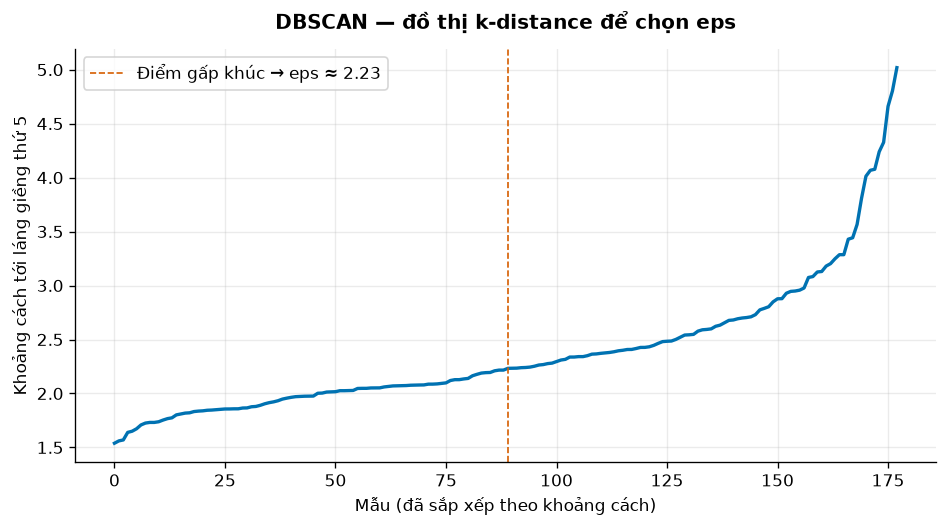

eps chọn theo điểm gấp khúc: 2.233 (min_samples=5)


In [38]:
K_DIST = 5
nn = NearestNeighbors(n_neighbors=K_DIST).fit(X_full_scaled)
distances, _ = nn.kneighbors(X_full_scaled)
k_dist = np.sort(distances[:, -1])

# Điểm gấp khúc: tiêu chí chord trên nửa trên của đường cong (tránh vấp ở đoạn đầu)
half = len(k_dist) // 2
tail = k_dist[half:]
chord = np.linspace(tail[0], tail[-1], len(tail))
knee_idx = half + int(np.argmax(tail - chord))
eps_chosen = float(k_dist[knee_idx])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.arange(len(k_dist)), k_dist, color="#0072B2", linewidth=2)
ax.axvline(knee_idx, color="#D55E00", linestyle="--", linewidth=1,
           label=f"Điểm gấp khúc → eps ≈ {eps_chosen:.2f}")
ax.set(xlabel="Mẫu (đã sắp xếp theo khoảng cách)", ylabel=f"Khoảng cách tới láng giềng thứ {K_DIST}",
       title="DBSCAN — đồ thị k-distance để chọn eps")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "11_dbscan_kdistance.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"eps chọn theo điểm gấp khúc: {eps_chosen:.3f} (min_samples={K_DIST})")

In [39]:
dbscan = DBSCAN(eps=eps_chosen, min_samples=K_DIST)
db_labels = dbscan.fit_predict(X_full_scaled)
n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = int((db_labels == -1).sum())
ari_db = adjusted_rand_score(y_full, db_labels)

print(f"DBSCAN (eps={eps_chosen:.3f}, min_samples={K_DIST}): "
      f"{n_clusters_db} cụm, {n_noise} điểm nhiễu ({n_noise/len(db_labels):.1%}), ARI = {ari_db:.4f}")
db_crosstab = pd.crosstab(pd.Series(db_labels, name="Cụm DBSCAN (-1 = nhiễu)"),
                          pd.Series(y_full, name="Lớp thật"))
display(db_crosstab)
save_table(db_crosstab, "11_dbscan_crosstab.csv", index=True)

# Bảng độ nhạy quanh eps đã chọn (tham khảo — không dùng để chọn lại tham số)
# Dùng đúng giá trị eps_chosen ở dòng giữa để tái lập chính xác kết quả đã fit.
sensitivity_rows = []
for eps in eps_chosen + np.array([-0.5, -0.25, 0.0, 0.25, 0.5]):
    lab = DBSCAN(eps=float(eps), min_samples=K_DIST).fit_predict(X_full_scaled)
    n_c = len(set(lab)) - (1 if -1 in lab else 0)
    sensitivity_rows.append({"eps": float(eps), "Số cụm": n_c,
                             "Số điểm nhiễu": int((lab == -1).sum()),
                             "ARI": round(adjusted_rand_score(y_full, lab), 4)})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)
save_table(sensitivity, "11_dbscan_sensitivity.csv")

DBSCAN (eps=2.233, min_samples=5): 2 cụm, 48 điểm nhiễu (27.0%), ARI = 0.3785


Lớp thật,1,2,3
Cụm DBSCAN (-1 = nhiễu),,,
-1,7,33,8
0,52,37,0
1,0,1,40


,eps,Số cụm,Số điểm nhiễu,ARI
0,1.73292,6,134,0.0322
1,1.98292,6,85,0.3170
2,2.23292,2,48,0.3785
3,2.48292,1,29,0.0185
4,2.73292,1,18,0.0003


WindowsPath('C:/Users/ASUS/Documents/code/thực hành/bài tập nhóm data mining/datasets/output/11_dbscan_sensitivity.csv')

### 4.4. Trực quan hóa kết quả gom cụm trên PCA 2D

Hai biểu đồ cạnh nhau theo đúng yêu cầu đề: điểm tô theo **cụm tìm được** (không phải nhãn thật); riêng DBSCAN, điểm nhiễu tô xám. Trục là PC1/PC2 của phép PCA fit trên toàn bộ dữ liệu chuẩn hóa.

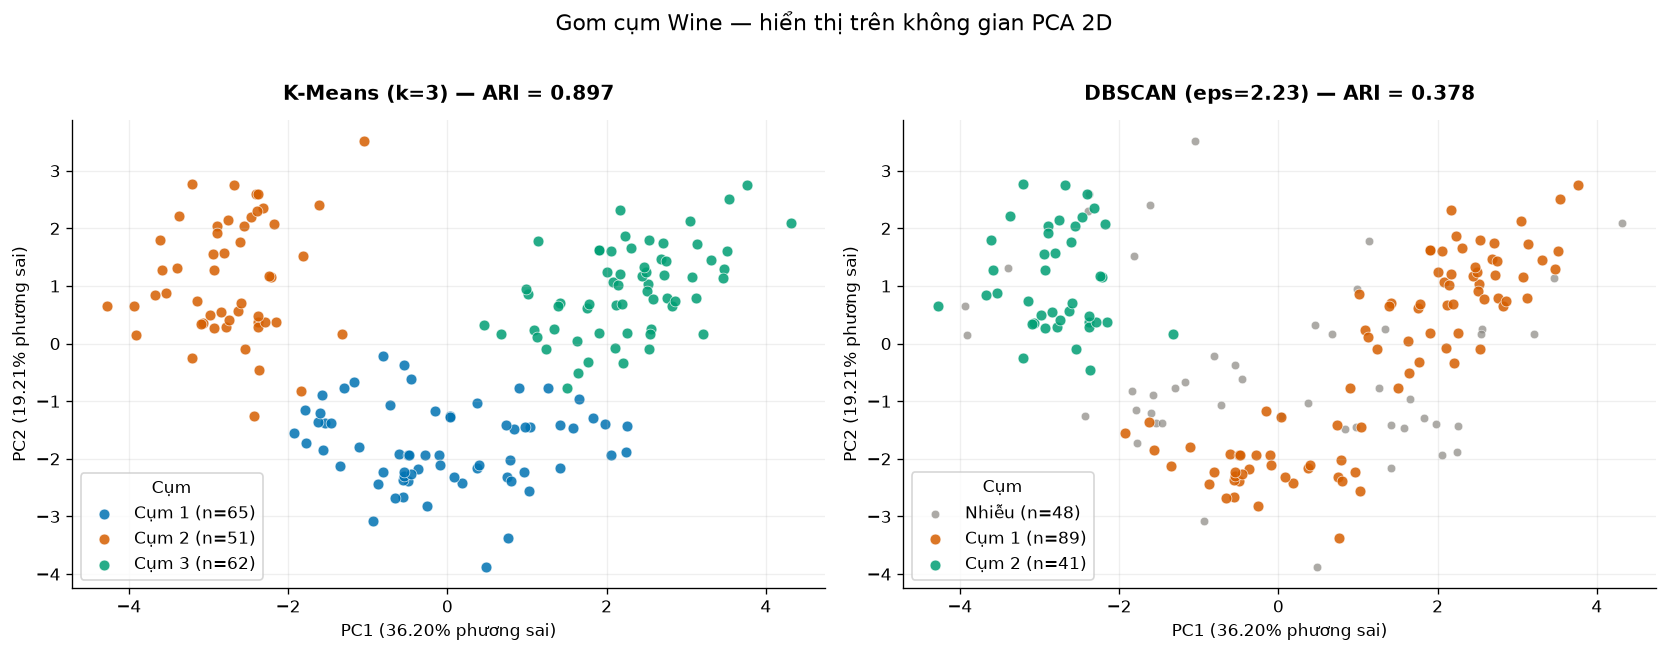

In [40]:
CLUSTER_PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00"]  # Okabe-Ito, đồng bộ phần 1-2
NOISE_COLOR = "#898781"

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for c in range(3):
    m = km_labels == c
    axes[0].scatter(coords_full[m, 0], coords_full[m, 1], s=42, alpha=0.85,
                    color=CLUSTER_PALETTE[c], edgecolors="white", linewidths=0.4,
                    label=f"Cụm {c + 1} (n={m.sum()})")
axes[0].set(title=f"K-Means (k=3) — ARI = {ari_km:.3f}",
            xlabel=f"PC1 ({v1_full:.2%} phương sai)", ylabel=f"PC2 ({v2_full:.2%} phương sai)")
axes[0].legend(title="Cụm")

for i, c in enumerate(sorted(set(db_labels))):
    m = db_labels == c
    if c == -1:
        axes[1].scatter(coords_full[m, 0], coords_full[m, 1], s=26, alpha=0.7,
                        color=NOISE_COLOR, edgecolors="white", linewidths=0.4,
                        label=f"Nhiễu (n={m.sum()})")
    else:
        axes[1].scatter(coords_full[m, 0], coords_full[m, 1], s=42, alpha=0.85,
                        color=CLUSTER_PALETTE[i % len(CLUSTER_PALETTE)],
                        edgecolors="white", linewidths=0.4,
                        label=f"Cụm {c + 1} (n={m.sum()})")
axes[1].set(title=f"DBSCAN (eps={eps_chosen:.2f}) — ARI = {ari_db:.3f}",
            xlabel=f"PC1 ({v1_full:.2%} phương sai)", ylabel=f"PC2 ({v2_full:.2%} phương sai)")
axes[1].legend(title="Cụm")

for ax in axes:
    ax.grid(alpha=0.2)
fig.suptitle("Gom cụm Wine — hiển thị trên không gian PCA 2D", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(FIGURE_DIR / "12_clustering_pca2d.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.5. Bảng đánh giá kết quả gom cụm

Độ đo chính theo đề: **Adjusted Rand Index** (đối chiếu cụm với nhãn thật). Bổ sung **Silhouette** (độ tách cụm trong không gian đặc trưng, không dùng nhãn; với DBSCAN chỉ tính trên các điểm không phải nhiễu).

In [41]:
sil_km = silhouette_score(X_full_scaled, km_labels)
non_noise = db_labels != -1
sil_db = (silhouette_score(X_full_scaled.loc[non_noise], db_labels[non_noise])
          if n_clusters_db >= 2 else float("nan"))

evaluation = pd.DataFrame([
    {"Giải thuật": "K-Means (k=3)", "Độ đo": "Adjusted Rand Index", "Giá trị": round(ari_km, 4)},
    {"Giải thuật": f"DBSCAN (eps={eps_chosen:.2f}, min_samples={K_DIST})",
     "Độ đo": "Adjusted Rand Index", "Giá trị": round(ari_db, 4)},
    {"Giải thuật": "K-Means (k=3)", "Độ đo": "Silhouette (bổ sung)", "Giá trị": round(sil_km, 4)},
    {"Giải thuật": f"DBSCAN (eps={eps_chosen:.2f}, min_samples={K_DIST})",
     "Độ đo": "Silhouette (bổ sung, bỏ nhiễu)", "Giá trị": round(sil_db, 4)},
])
display(evaluation)
save_table(evaluation, "11_clustering_evaluation.csv")

,Giải thuật,Độ đo,Giá trị
0,K-Means (k=3),Adjusted Rand Index,0.8975
1,"DBSCAN (eps=2.23, min_samples=5)",Adjusted Rand Index,0.3785
2,K-Means (k=3),Silhouette (bổ sung),0.2849
3,"DBSCAN (eps=2.23, min_samples=5)","Silhouette (bổ sung, bỏ nhiễu)",0.3386


WindowsPath('C:/Users/ASUS/Documents/code/thực hành/bài tập nhóm data mining/datasets/output/11_clustering_evaluation.csv')

In [42]:
display(Markdown(f"""
**Nhận xét phần gom cụm.**
- **K-Means (k=3)** đạt ARI = **{ari_km:.4f}** — các cụm tìm được khớp phần lớn với 3 lớp thật; bảng chéo cho thấy mỗi cụm ứng gần như trọn vẹn một lớp. Điều này nhất quán với EDA và PCA 2D: 3 lớp có cấu trúc tách rõ trong không gian thuộc tính chuẩn hóa.
- **DBSCAN** (eps = {eps_chosen:.3f} chọn từ điểm gấp khúc k-distance, min_samples = {K_DIST}) tìm được **{n_clusters_db} cụm** và **{n_noise} điểm nhiễu** ({n_noise/len(db_labels):.1%}), ARI = **{ari_db:.4f}**. Trong không gian 13 chiều chuẩn hóa, mật độ giữa các vùng không đồng đều: vùng chuyển tiếp giữa hai lớp đủ dày để DBSCAN nối chúng thành một cụm, trong khi các điểm thưa bị gắn nhiễu. Vì vậy ARI thấp hơn hẳn K-Means — kết quả này phản ánh đúng điểm yếu của phương pháp dựa mật độ trên bộ Wine chứ không phải lỗi cài đặt. Bảng độ nhạy cho thấy số cụm và số điểm nhiễu thay đổi mạnh theo eps, đặc trưng của phương pháp dựa mật độ.
- ARI chỉ dùng để **đánh giá** sau khi gom cụm; nhãn không tham gia chọn k, eps hay fit mô hình.
"""))


**Nhận xét phần gom cụm.**
- **K-Means (k=3)** đạt ARI = **0.8975** — các cụm tìm được khớp phần lớn với 3 lớp thật; bảng chéo cho thấy mỗi cụm ứng gần như trọn vẹn một lớp. Điều này nhất quán với EDA và PCA 2D: 3 lớp có cấu trúc tách rõ trong không gian thuộc tính chuẩn hóa.
- **DBSCAN** (eps = 2.233 chọn từ điểm gấp khúc k-distance, min_samples = 5) tìm được **2 cụm** và **48 điểm nhiễu** (27.0%), ARI = **0.3785**. Trong không gian 13 chiều chuẩn hóa, mật độ giữa các vùng không đồng đều: vùng chuyển tiếp giữa hai lớp đủ dày để DBSCAN nối chúng thành một cụm, trong khi các điểm thưa bị gắn nhiễu. Vì vậy ARI thấp hơn hẳn K-Means — kết quả này phản ánh đúng điểm yếu của phương pháp dựa mật độ trên bộ Wine chứ không phải lỗi cài đặt. Bảng độ nhạy cho thấy số cụm và số điểm nhiễu thay đổi mạnh theo eps, đặc trưng của phương pháp dựa mật độ.
- ARI chỉ dùng để **đánh giá** sau khi gom cụm; nhãn không tham gia chọn k, eps hay fit mô hình.


## Tổng kết toàn bài

| Phần | Nội dung | Kết quả chính |
|---|---|---|
| 1 | Đọc & khám phá, làm sạch | 178 mẫu × 13 thuộc tính liên tục + nhãn; không thiếu/lỗi; chia train 142 / test 36 phân tầng, seed 42 |
| 2 | Tạo data mới & trực quan | Chuẩn hóa fit trên train; PCA 2D theo nhãn; bảng phương sai và hệ số PC; toàn bộ CSV/PNG lưu trong `datasets/output/` |
| 3 | Phân loại 3 mô hình | Nested stratified 10-fold CV, F1-macro; bảng xếp hạng Random Forest / KNN / Gaussian Naive Bayes kèm tham số tốt nhất |
| 4 | Gom cụm | K-Means (k=3) và DBSCAN (eps từ k-distance); đánh giá ARI + Silhouette; trực quan PCA 2D |

**Lưu ý tái lập:** chạy tuần tự từ đầu; phần 3 đọc các CSV do phần 1–2 sinh ra trong `datasets/output/`; phần 4 dùng dữ liệu đầy đủ 178 mẫu. Toàn bộ bảng số liệu và nhận định định lượng của phần 3 được tính trực tiếp từ kết quả chạy trong notebook (không hard-code), nên chạy lại với cùng seed và dữ liệu sẽ tái lập cùng số liệu.